# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

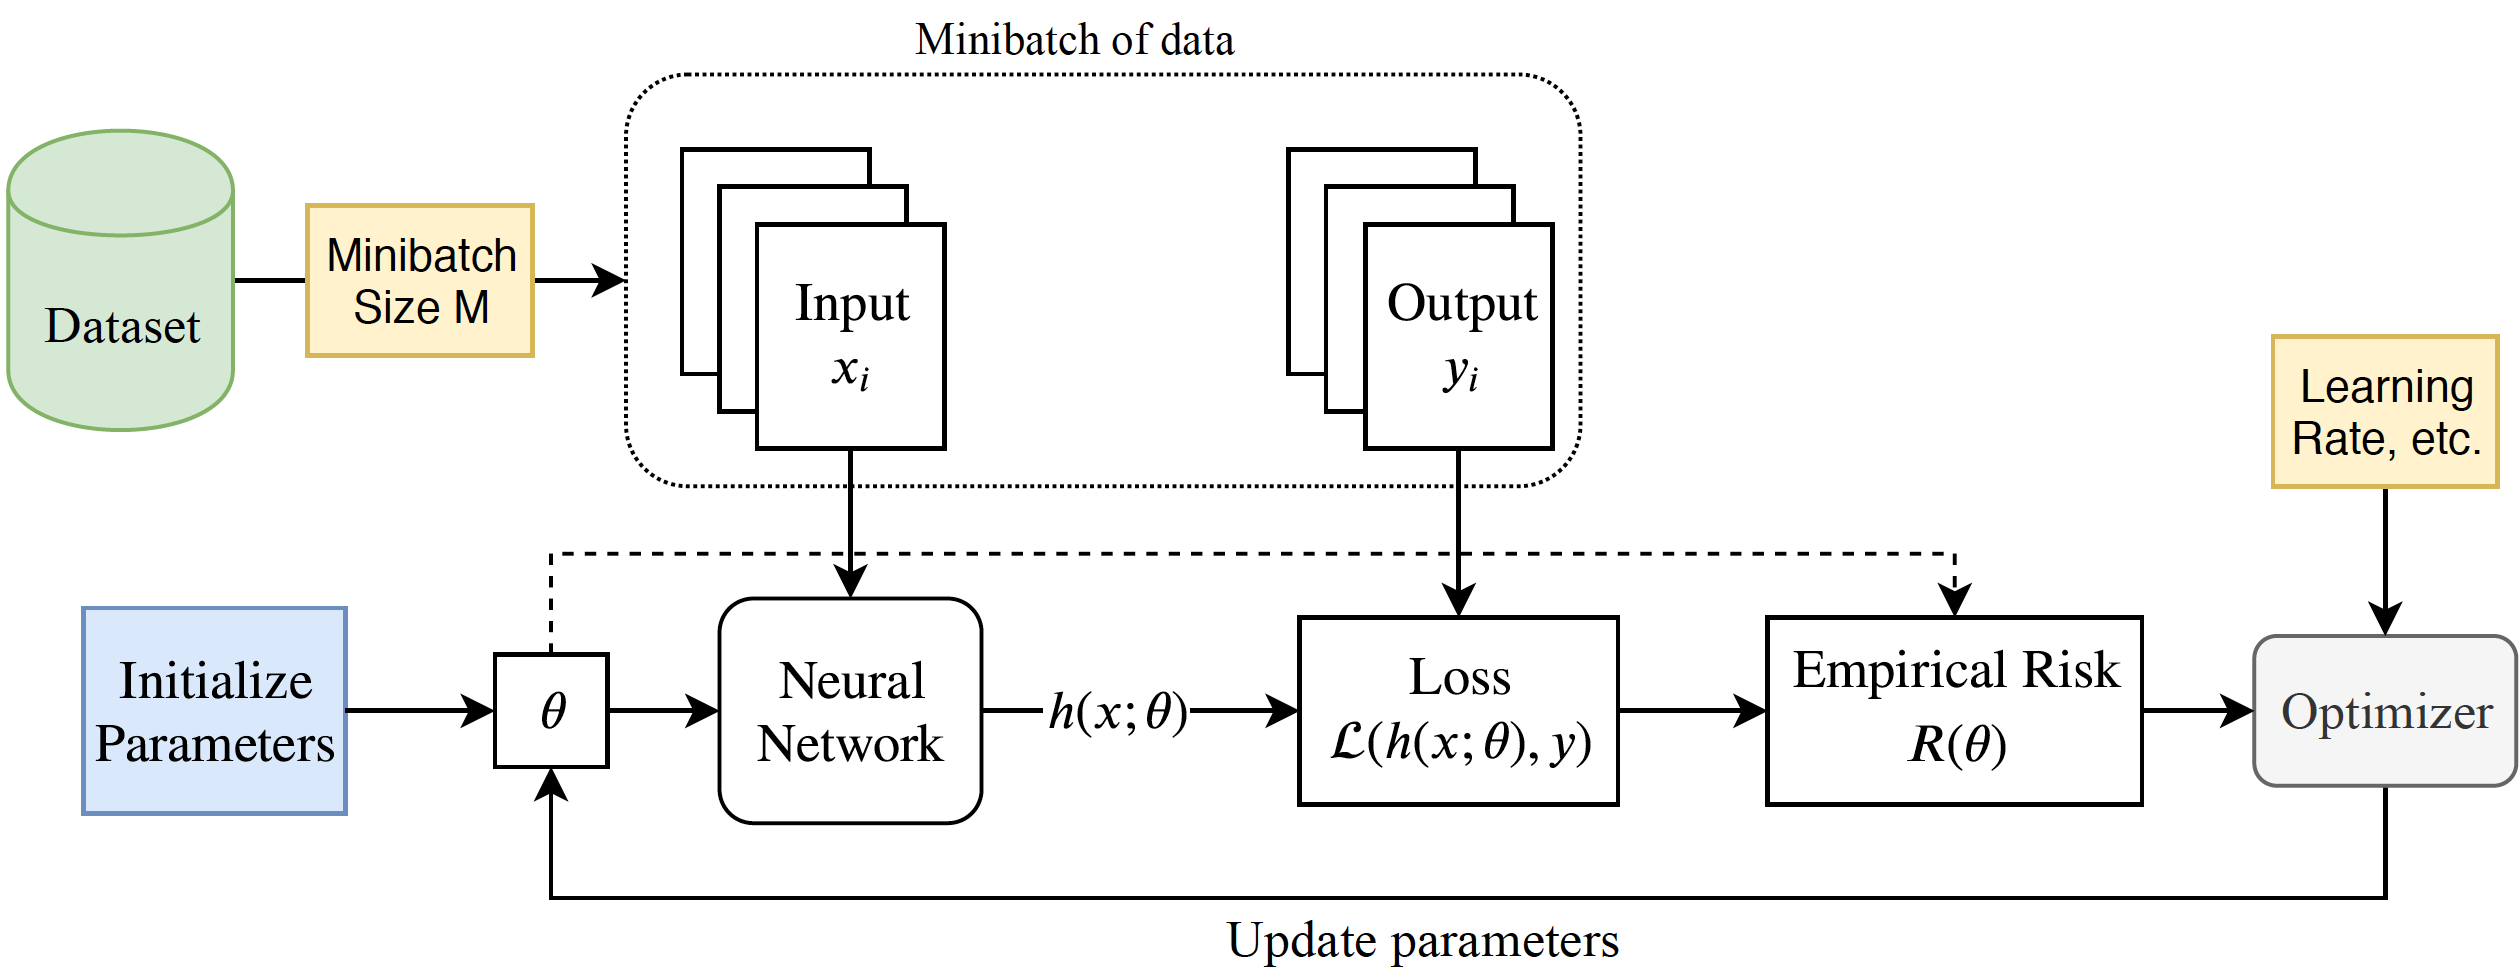

## 0 · Setup

In [3]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cuda


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


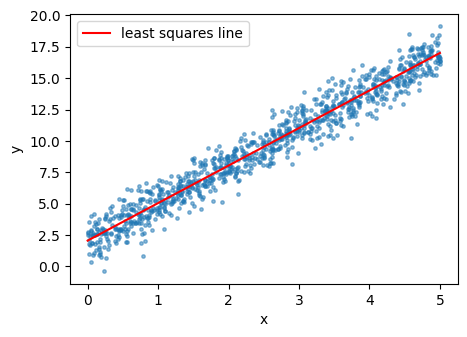

In [4]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [5]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 1 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [6]:
hist_sgd = train_toy(batch_size=1)

epoch  1 | J = 1.0230 | w = 2.891, b = 2.075
epoch  2 | J = 0.9702 | w = 3.026, b = 2.103
epoch  3 | J = 0.9785 | w = 3.060, b = 2.020
epoch  4 | J = 1.0928 | w = 3.165, b = 1.898
epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch  6 | J = 0.9735 | w = 3.021, b = 2.131
epoch  7 | J = 1.0184 | w = 2.892, b = 2.084
epoch  8 | J = 0.9566 | w = 3.013, b = 2.081
epoch  9 | J = 1.0841 | w = 2.855, b = 2.087
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 11 | J = 1.0366 | w = 3.056, b = 2.174
epoch 12 | J = 1.0330 | w = 3.068, b = 2.130
epoch 13 | J = 1.0759 | w = 3.090, b = 2.132
epoch 14 | J = 1.0242 | w = 2.915, b = 1.997
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 16 | J = 1.3911 | w = 2.786, b = 1.976
epoch 17 | J = 1.0375 | w = 2.872, b = 2.112
epoch 18 | J = 0.9864 | w = 3.090, b = 1.933
epoch 19 | J = 0.9582 | w = 3.017, b = 2.076
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 7.91 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [7]:
hist_mb = train_toy(batch_size=32)

epoch  1 | J = 8.3765 | w = 1.290, b = 7.434
epoch  2 | J = 6.4393 | w = 1.595, b = 6.707
epoch  3 | J = 4.9947 | w = 1.744, b = 6.033
epoch  4 | J = 3.9405 | w = 1.904, b = 5.466
epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch  6 | J = 2.5936 | w = 2.240, b = 4.604
epoch  7 | J = 2.1565 | w = 2.310, b = 4.232
epoch  8 | J = 1.8781 | w = 2.474, b = 3.953
epoch  9 | J = 1.6184 | w = 2.477, b = 3.674
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 11 | J = 1.3177 | w = 2.637, b = 3.265
epoch 12 | J = 1.2207 | w = 2.670, b = 3.093
epoch 13 | J = 1.1542 | w = 2.734, b = 2.958
epoch 14 | J = 1.1020 | w = 2.739, b = 2.826
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 16 | J = 1.0336 | w = 2.810, b = 2.636
epoch 17 | J = 1.0126 | w = 2.829, b = 2.556
epoch 18 | J = 0.9964 | w = 2.867, b = 2.491
epoch 19 | J = 0.9886 | w = 2.900, b = 2.435
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.32 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [8]:
hist_mom = train_toy(batch_size=64, momentum=0.9)

epoch  1 | J = 6.1264 | w = 1.434, b = 5.922
epoch  2 | J = 1.4561 | w = 2.634, b = 3.438
epoch  3 | J = 1.0152 | w = 3.024, b = 2.225
epoch  4 | J = 0.9865 | w = 3.092, b = 1.923
epoch  5 | J = 0.9673 | w = 3.071, b = 1.918
epoch  6 | J = 0.9700 | w = 3.055, b = 2.005
epoch  7 | J = 0.9650 | w = 3.032, b = 2.063
epoch  8 | J = 1.0744 | w = 3.099, b = 2.102
epoch  9 | J = 0.9555 | w = 3.013, b = 2.073
epoch 10 | J = 0.9531 | w = 2.964, b = 2.075
epoch 11 | J = 0.9698 | w = 2.941, b = 2.056
epoch 12 | J = 0.9842 | w = 2.928, b = 2.052
epoch 13 | J = 0.9596 | w = 2.954, b = 2.062
epoch 14 | J = 0.9543 | w = 3.008, b = 2.081
epoch 15 | J = 0.9756 | w = 3.041, b = 2.074
epoch 16 | J = 0.9545 | w = 3.009, b = 2.079
epoch 17 | J = 0.9496 | w = 2.985, b = 2.056
epoch 18 | J = 0.9775 | w = 3.036, b = 2.098
epoch 19 | J = 0.9519 | w = 3.004, b = 2.070
epoch 20 | J = 0.9505 | w = 3.005, b = 2.048
updates: 320 | training time: 0.17 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

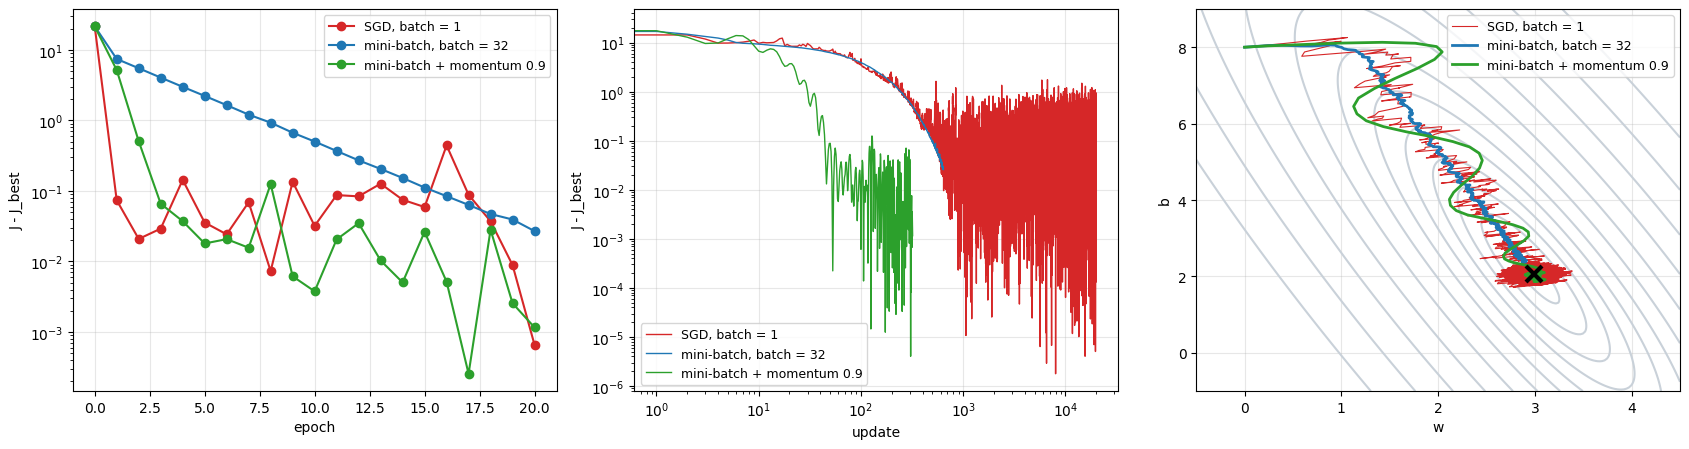

SGD, batch = 1               updates:  20000 | time: 7.91 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.32 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    320 | time: 0.17 s | final J - J_best: 0.0012


In [9]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 347kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.1MB/s]


train (54000, 784) | val (6000, 784) | test (10000, 784)


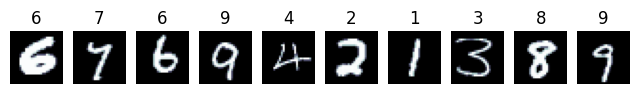

In [10]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [11]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [12]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.2743 | val loss 0.1614 | val acc 95.08% | 2.3 s
epoch  2 | lr 1.00e-03 | train loss 0.1180 | val loss 0.1251 | val acc 96.15% | 4.0 s
epoch  3 | lr 1.00e-03 | train loss 0.0840 | val loss 0.0955 | val acc 97.03% | 6.0 s
epoch  4 | lr 1.00e-03 | train loss 0.0620 | val loss 0.0803 | val acc 97.40% | 8.0 s
epoch  5 | lr 1.00e-03 | train loss 0.0510 | val loss 0.0833 | val acc 97.43% | 9.7 s
epoch  6 | lr 1.00e-03 | train loss 0.0412 | val loss 0.0867 | val acc 97.52% | 11.5 s
epoch  7 | lr 1.00e-03 | train loss 0.0351 | val loss 0.0944 | val acc 97.22% | 13.3 s
epoch  8 | lr 1.00e-03 | train loss 0.0310 | val loss 0.1220 | val acc 96.82% | 15.0 s
epoch  9 | lr 1.00e-03 | train loss 0.0274 | val loss 0.0923 | val acc 97.78% | 16.8 s
epoch 10 | lr 1.00e-03 | train loss 0.0229 | val loss 0.1100 | val acc 97.40% | 18.8 s


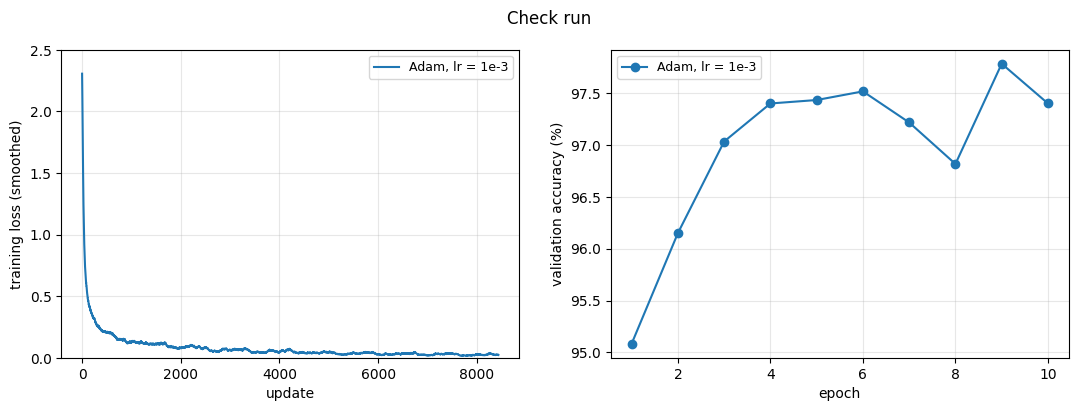

In [13]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 0.3066 | val loss 0.1598 | val acc 95.05% | 1.7 s
epoch  2 | lr 1.00e-01 | train loss 0.1169 | val loss 0.1095 | val acc 96.67% | 3.2 s
epoch  3 | lr 1.00e-01 | train loss 0.0820 | val loss 0.0984 | val acc 96.95% | 4.7 s
epoch  4 | lr 1.00e-01 | train loss 0.0594 | val loss 0.0945 | val acc 96.97% | 6.2 s
epoch  5 | lr 1.00e-01 | train loss 0.0465 | val loss 0.0845 | val acc 97.30% | 7.7 s
epoch  6 | lr 1.00e-01 | train loss 0.0357 | val loss 0.0929 | val acc 97.45% | 9.2 s
epoch  7 | lr 1.00e-01 | train loss 0.0273 | val loss 0.0848 | val acc 97.53% | 10.8 s
epoch  8 | lr 1.00e-01 | train loss 0.0220 | val loss 0.0878 | val acc 97.62% | 12.6 s
epoch  9 | lr 1.00e-01 | train loss 0.0166 | val loss 0.0936 | val acc 97.52% | 14.2 s
epoch 10 | lr 1.00e-01 | train loss 0.0114 | val loss 0.0804 | val acc 97.60% | 15.7 s


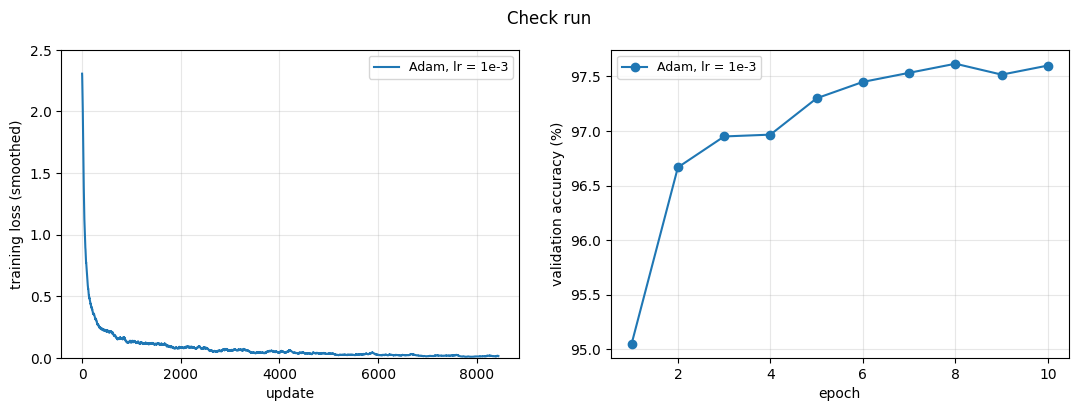

In [14]:
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 262.4336 | val loss 2.3613 | val acc 12.52% | 1.8 s
epoch  2 | lr 1.00e-01 | train loss 4.0392 | val loss 2.6357 | val acc 9.67% | 3.7 s
epoch  3 | lr 1.00e-01 | train loss 3.1509 | val loss 2.3837 | val acc 11.10% | 5.5 s
epoch  4 | lr 1.00e-01 | train loss 2.3282 | val loss 2.3652 | val acc 9.62% | 7.3 s
epoch  5 | lr 1.00e-01 | train loss 2.3118 | val loss 2.3656 | val acc 9.58% | 9.3 s
epoch  6 | lr 1.00e-01 | train loss 2.3109 | val loss 2.3592 | val acc 11.10% | 11.2 s
epoch  7 | lr 1.00e-01 | train loss 2.3110 | val loss 2.3650 | val acc 11.10% | 13.0 s
epoch  8 | lr 1.00e-01 | train loss 2.3115 | val loss 2.3591 | val acc 9.70% | 14.7 s
epoch  9 | lr 1.00e-01 | train loss 2.3113 | val loss 2.3578 | val acc 10.37% | 16.4 s
epoch 10 | lr 1.00e-01 | train loss 2.3112 | val loss 2.3616 | val acc 9.95% | 18.2 s


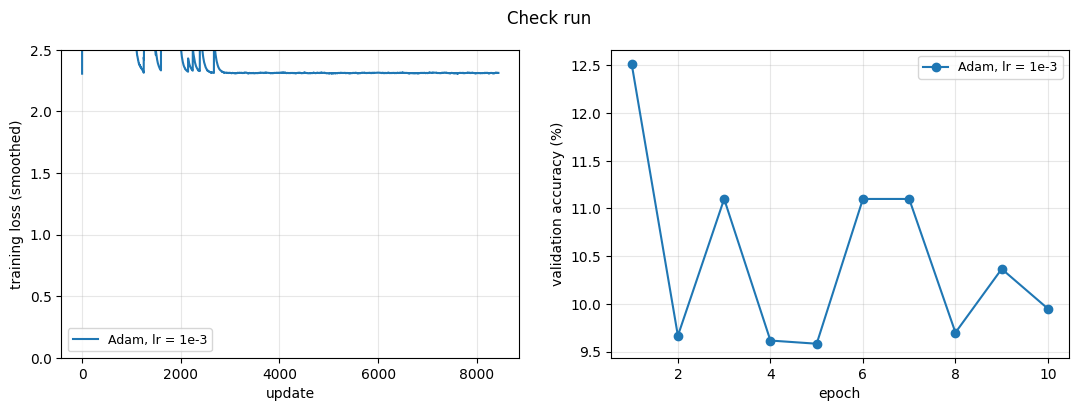

In [15]:
model = make_model(seed=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

=== SGD, lr = 1 ===
=== SGD, lr = 0.3 ===
=== SGD, lr = 0.1 ===
=== SGD, lr = 0.03 ===
=== SGD, lr = 0.01 ===
=== SGD, lr = 0.001 ===


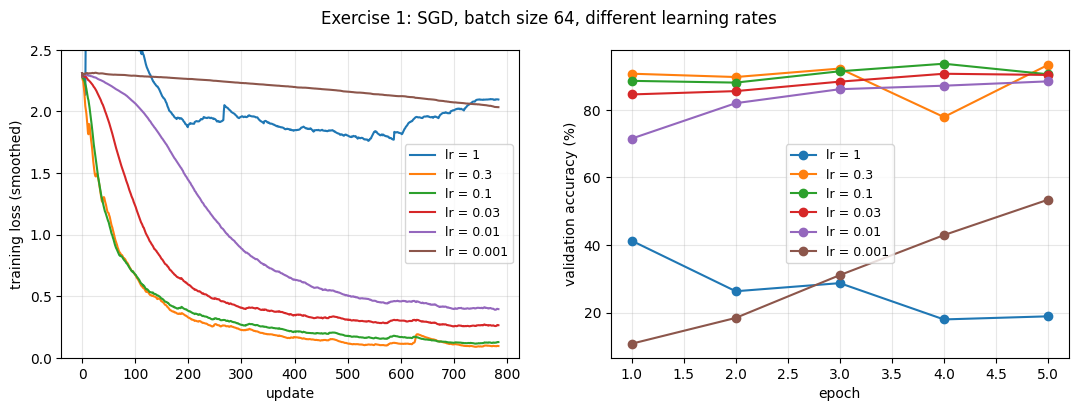


learning rate   best val acc  final val acc  final train loss  diverged
lr = 1                41.28%         18.92%            2.0679  False
lr = 0.3              93.27%         93.27%            0.1064  False
lr = 0.1              93.62%         90.50%            0.1164  False
lr = 0.03             90.65%         90.30%            0.2572  False
lr = 0.01             88.40%         88.40%            0.3938  False
lr = 0.001            53.40%         53.40%            2.0486  False


In [16]:
# Exercise 1: the learning rate of SGD
# SGD without momentum, batch size 64, 5 epochs, first 10,000 training examples,
# same initial weights (make_model(seed=0)) and same mini-batch order for every run.

lrs = [1, 0.3, 0.1, 0.03, 0.01, 0.001]
hists1 = {}

for lr in lrs:
    print(f"=== SGD, lr = {lr} ===")
    model = make_model(seed=0)                                   # same starting weights every time
    optimizer = optim.SGD(model.parameters(), lr=lr)             # plain SGD: no momentum
    loader = make_loader(batch_size=64, n_train=10_000)          # same data order every time
    hists1[f"lr = {lr}"] = fit(model, optimizer, loader, epochs=5, verbose=False)

# 2. plot the six runs on one figure
plot_history(hists1, "Exercise 1: SGD, batch size 64, different learning rates")

# 3. best validation accuracy of each run (plus a few extra numbers to help the explanation)
print(f"\n{'learning rate':14s} {'best val acc':>13s} {'final val acc':>14s} {'final train loss':>17s}  diverged")
for name, h in hists1.items():
    print(f"{name:14s} {max(h['val_acc']):12.2f}% {h['val_acc'][-1]:13.2f}% {h['train_loss'][-1]:17.4f}  {h['diverged']}")

**Exercise 1: your observations and explanation.** *Write here.*

### 1. What was done

Six models (MLP 784 → 128 → 100 → 10) were trained with plain SGD (no momentum), batch size 64, for 5 epochs on the first 10,000 training images (157 updates per epoch, 785 updates in total). The learning rates were $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$. All runs have the same initial weights (`make_model(seed=0)`) and the same mini-batch order, so **the learning rate is the only difference between the runs**.

### 2. Background: what the learning rate does

At each update SGD computes the gradient $\nabla J$ of the loss on one mini-batch, which points in the direction where the loss increases fastest, and moves the parameters in the opposite direction:

$$\theta \leftarrow \theta - \alpha \, \nabla J^{\{t\}}$$

The learning rate $\alpha$ is the **size of the step**. Think of walking down a foggy hill: the gradient tells you which way is down, and $\alpha$ tells you how far you walk before checking again.

* **$\alpha$ too small**: the steps are tiny, so after a fixed number of updates you have barely moved.
* **$\alpha$ well chosen**: you go down quickly and reach a low loss.
* **$\alpha$ too large**: a step jumps over the valley and lands higher on the other side, so the loss goes up instead of down.

A useful reference: the network has 10 output classes, and a model that guesses uniformly has a cross-entropy loss of $\ln 10 \approx 2.30$ and an accuracy of 10%. This is where every run starts (all curves start at 2.3 in the figure). A run that stays near 2.3 has learned almost nothing.

### 3. Results

| Learning rate | best val acc | final val acc | final train loss |
|---|---|---|---|
| 1 | 41.28% | 18.92% | 2.0679 |
| 0.3 | 93.27% | 93.27% | **0.1064** |
| 0.1 | **93.62%** | 90.50% | 0.1164 |
| 0.03 | 90.65% | 90.30% | 0.2572 |
| 0.01 | 88.40% | 88.40% | 0.3938 |
| 0.001 | 53.40% | 53.40% | 2.0486 |

None of the runs produced `nan` or `inf`, so the `diverged` flag is `False` for all of them. This flag only detects a loss that becomes `nan` or `inf`; it does not mean that every run trained well (see $\alpha = 1$ below).

### 4. Observations

**$\alpha = 1$: too large, training fails.**
* The training loss jumps far *above* the starting value 2.3 in the first updates (the blue curve leaves the top of the plot, which is cut at 2.5), then comes back to about 1.9, wanders, and **increases again** to about 2.1 at the end. The final loss (2.07) is barely below the starting value 2.30.
* The validation accuracy is bad and unstable: 41% after epoch 1, which is the best it ever gets, then 26%, 29%, 18% and finally 18.9%. It gets **worse as training continues**, and the final value is only slightly above the 10% of random guessing.
* The loss did not become `nan`, so the run did not "diverge" in the technical sense, but it clearly failed to learn: the steps are so large that the parameters are thrown around instead of descending.

**$\alpha = 0.3$ and $\alpha = 0.1$: the best runs.**
* They have the **fastest descent**: the loss drops from 2.3 to about 0.5 in the first 100 updates, and ends at 0.106 (for 0.3, the lowest of all) and 0.116 (for 0.1).
* Their validation accuracy is already about 91% (0.3) and 88% (0.1) after the first epoch, and reaches 93.3% and 93.6% at best.
* They are not perfectly smooth: both curves have a small bump near update 630, $\alpha = 0.3$ has a drop of the validation accuracy to about 78% at epoch 4 (then recovers to 93.27% at epoch 5), and $\alpha = 0.1$ goes from about 94% at epoch 4 to 90.5% at epoch 5 although its training loss does not increase. These are signs of the **noise of large steps**: the parameters are close to a good region but keep jumping slightly around it.

**$\alpha = 0.03$ and $\alpha = 0.01$: stable but slower.**
* Smooth curves with no bumps. The loss decreases more slowly (final 0.257 and 0.394) and the accuracy ends at 90.3% and 88.4%.
* At $\alpha = 0.01$ the epoch-1 accuracy is only about 71% (against 91% for 0.3). The loss and the accuracy of both runs were **still improving** when the 5 epochs ended: they would continue to improve with more epochs.

**$\alpha = 0.001$: too small.**
* The loss goes from 2.30 to only 2.05 in 785 updates: almost a straight, very gentle line. The accuracy goes up steadily (11% → 19% → 31% → 43% → 53%), but it is still 40 points below the best runs after 5 epochs. The model is far from converged.

**A remarkable comparison.** The final training losses of $\alpha = 1$ (2.07) and $\alpha = 0.001$ (2.05) are almost the same, but for **opposite reasons**: the first run bounces around because its steps are too big, the second one has hardly moved because its steps are too small. The loss alone does not say what went wrong: the shape of the curve does (noisy and jumping vs smooth and slowly decreasing), and so does the accuracy over epochs (decreasing vs increasing).

### 5. Explanations

* **Why the smaller rates are slower.** The change of the parameters in one update is proportional to $\alpha$. With a fixed budget of 785 updates, a rate 10 times smaller travels about 10 times less far: that is why the order of the final losses follows the order of the learning rates (0.3 < 0.1 < 0.03 < 0.01 < 0.001). These runs are not bad because they would end at a bad place, they are bad because **they run out of time**: the model is *underfitted because training was too short for that rate*, and more epochs would help.
* **Why $\alpha = 1$ fails.** The gradient is multiplied by 1, so a single bad mini-batch can change the weights enormously. The weights become large, the outputs of the network become large and wrong, the cross-entropy loss becomes large (we see values above 2.5), and the gradients computed at that point are again large. The parameters never stay in a region where descent is possible. (With even larger rates, or by bad luck, the loss would reach `nan` or `inf`, which `fit` would report as divergence.)
* **Why the largest rate is not the best.** The speed gain stops when the step becomes larger than the width of the valley. Between 0.001 and 0.3 each increase of $\alpha$ helps, 0.3 is still fine, but at 1 training breaks. The best learning rate is therefore **close to, but below, the largest stable value**: here 0.1 to 0.3.
* **Why 0.1 and 0.3 are equivalent here.** The best validation accuracies are 93.62% (0.1) and 93.27% (0.3). The validation set has 6,000 images, so the difference of 0.35 points is about 21 images: too small to say that one is better, especially with a single seed. $\alpha = 0.3$ has the lowest training loss and is faster at the beginning, but it is also less stable (the dip at epoch 4). $\alpha = 0.1$ is a good compromise, but its last epoch shows that it also has some noise. The **final** accuracy of $\alpha = 0.1$ (90.5%) is lower than its best (93.62%), which shows that comparing runs only by the best epoch can be misleading when the curve is noisy.
* **Why use a log grid.** What matters for the learning rate is its *order of magnitude*: going from 0.001 to 0.01 changed the accuracy from 53% to 88%, but going from 0.1 to 0.3 changed almost nothing. That is why we try values like 1, 0.3, 0.1, 0.03, ..., each about 3 times the previous one, rather than 0.1, 0.2, 0.3, ...
* **Why we judge on the validation set.** The learning rate is a hyperparameter, chosen using the validation accuracy. The test set is reserved for Exercise 8.

### 6. Conclusion

The learning rate controls a speed/stability trade-off. For plain SGD with batch size 64 on this problem and a budget of 5 epochs:

* $\alpha = 1$ is **too large**: unstable training, accuracy decreasing to 18.9%.
* $\alpha = 0.001$ is **too small**: stable but so slow that the accuracy is only 53.4%.
* The **useful range is 0.03 to 0.3**, with the best results for $\alpha = 0.1$ and $\alpha = 0.3$ (about 93.3-93.6%, final training loss about 0.11). The smaller rates in this range (0.03, 0.01) are stable but need more epochs.

This also shows two things that the next exercises explore: the best rate depends on the other choices (batch size, momentum, optimizer), and a large rate at the start followed by smaller rates (a schedule, Exercise 5) can combine the speed of 0.3 with the stability of the small rates.

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


######## SGD, lr = 0.01, 3 epochs ########
batch size  updates/epoch  time/epoch (s)  best val acc  final val acc
         1          10000           13.39        93.57%         93.20%
        32            313            0.52        88.87%         88.87%
       256             40            0.15        64.63%         64.63%
     10000              1            0.12         9.80%          9.78%


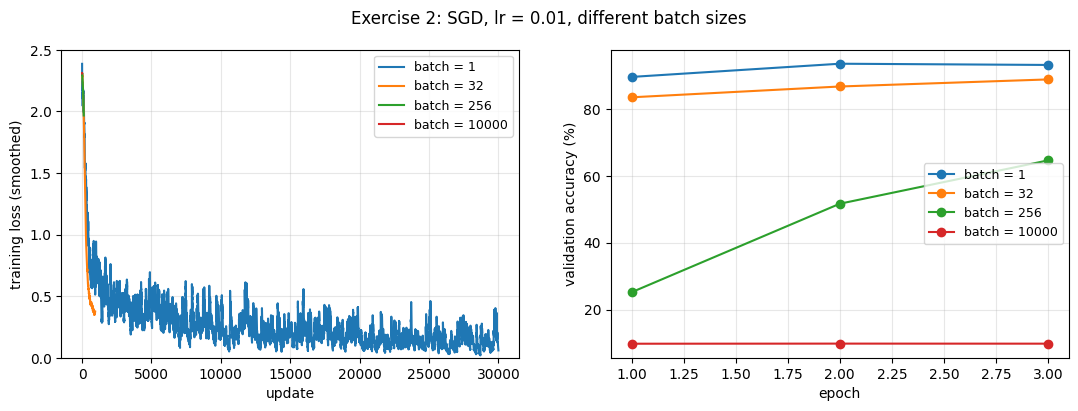

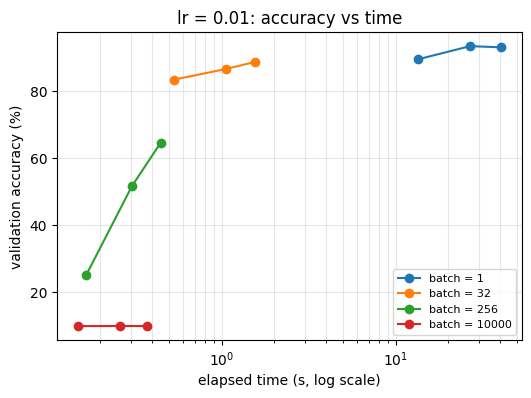


######## SGD, lr = 0.1, 3 epochs ########
batch size  updates/epoch  time/epoch (s)  best val acc  final val acc
diverged (loss is nan or inf): stopping
         1          10000            8.72         9.95%          9.72%
        32            313            0.53        93.57%         93.57%
       256             40            0.13        74.63%         74.63%
     10000              1            0.08        17.55%         17.55%


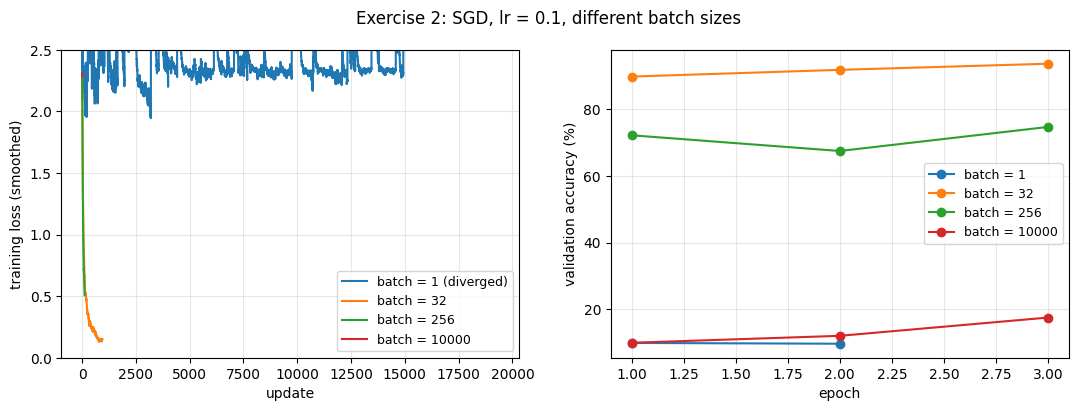

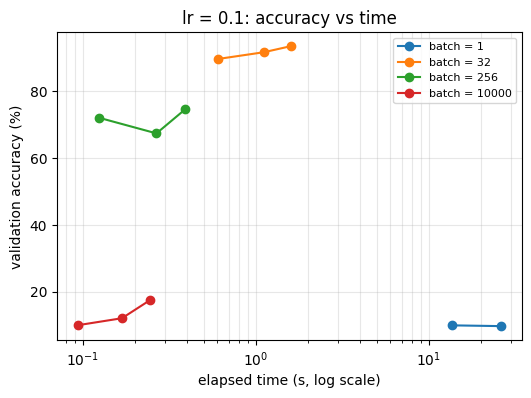

In [17]:
# Exercise 2: batch size (one example, mini-batches, the full set)
# SGD without momentum, 3 epochs, first 10,000 training examples,
# same initial weights (make_model(seed=0)) and same data order (make_loader seed=0).
# Steps 1-3 are done for alpha = 0.01, then repeated (step 4) for alpha = 0.1.

batch_sizes = [1, 32, 256, 10_000]
EPOCHS2 = 3

def run_batch_size_experiment(lr):
    hists = {}
    print(f"\n######## SGD, lr = {lr}, {EPOCHS2} epochs ########")
    print(f"{'batch size':>10s} {'updates/epoch':>14s} {'time/epoch (s)':>15s} {'best val acc':>13s} {'final val acc':>14s}")
    for bs in batch_sizes:
        model = make_model(seed=0)                                  # same starting weights
        optimizer = optim.SGD(model.parameters(), lr=lr)            # plain SGD, no momentum
        loader = make_loader(batch_size=bs, n_train=10_000)
        h = fit(model, optimizer, loader, epochs=EPOCHS2, verbose=False)
        hists[f"batch = {bs}"] = h
        updates_per_epoch = len(loader)                             # number of mini-batches = updates per epoch
        time_per_epoch = h["time"][-1] / EPOCHS2                    # h["time"] is cumulative: total time / epochs
        print(f"{bs:10d} {updates_per_epoch:14d} {time_per_epoch:15.2f} {max(h['val_acc']):12.2f}% {h['val_acc'][-1]:13.2f}%")
    return hists

def plot_vs_time(hists, title):
    # validation accuracy against the elapsed wall-clock time (one point per epoch)
    plt.figure(figsize=(6, 4))
    for name, h in hists.items():
        plt.plot(h["time"], h["val_acc"], "o-", label=name)
    plt.xscale("log"); plt.xlabel("elapsed time (s, log scale)"); plt.ylabel("validation accuracy (%)")
    plt.title(title); plt.grid(alpha=0.3, which="both"); plt.legend(fontsize=8); plt.show()

# --- alpha = 0.01 ---
hists2_a = run_batch_size_experiment(lr=0.01)
plot_history(hists2_a, "Exercise 2: SGD, lr = 0.01, different batch sizes")
plot_vs_time(hists2_a, "lr = 0.01: accuracy vs time")

# --- alpha = 0.1 (step 4) ---
hists2_b = run_batch_size_experiment(lr=0.1)
plot_history(hists2_b, "Exercise 2: SGD, lr = 0.1, different batch sizes")
plot_vs_time(hists2_b, "lr = 0.1: accuracy vs time")

**Exercise 2: your observations and explanation.** *Write here.*

### 1. What was done

The MLP was trained with plain SGD (no momentum) for 3 epochs on 10,000 training images, with four batch sizes: 1, 32, 256 and 10,000. All runs have the same initial weights and the same data, so **only the batch size changes**. The whole experiment was done for $\alpha = 0.01$ and repeated for $\alpha = 0.1$.

### 2. Background: epoch, batch, update

* An **epoch** is one pass over the 10,000 training images.
* The **batch size** $B$ is the number of images used for one parameter update. SGD computes the *average* gradient of the $B$ images and takes one step: $\theta \leftarrow \theta - \alpha\,\bar g_B$.
* The number of updates per epoch is therefore $\lceil 10000/B \rceil$:

| Batch size | Name | Updates per epoch | Updates in 3 epochs |
|---|---|---|---|
| 1 | SGD with one example per update | 10,000 | 30,000 |
| 32 | mini-batch SGD | 313 | 939 |
| 256 | mini-batch SGD | 40 | 120 |
| 10,000 | batch gradient descent (the whole set) | 1 | 3 |

Two facts explain the whole exercise:

1. **Quality of an update.** The average over $B$ examples has the same expected value as the true gradient (the average over all data), but its **noise shrinks as $B$ grows** (variance proportional to $1/B$). One example gives a very noisy direction; the whole set gives an exact one.
2. **Cost of an update.** The computer processes the $B$ examples at once (matrix operations), so an update on 32 examples does not cost 32 times more than one on 1 example. Each update has a large **fixed cost** (Python loop, launching the operations, optimizer step), and that cost is the same whatever $B$ is.

### 3. Results

**$\alpha = 0.01$**

| Batch size | Updates / epoch | Time / epoch (s) | Best val acc | Final val acc |
|---|---|---|---|---|
| 1 | 10,000 | 14.88 | **93.57%** | 93.20% |
| 32 | 313 | 0.54 | 88.87% | 88.87% |
| 256 | 40 | 0.19 | 64.63% | 64.63% |
| 10,000 | 1 | 0.24 | 9.80% | 9.78% |

**$\alpha = 0.1$**

| Batch size | Updates / epoch | Time / epoch (s) | Best val acc | Final val acc |
|---|---|---|---|---|
| 1 | 10,000 | 9.58 (see note) | 9.95% | 9.72% (**diverged**) |
| 32 | 313 | 0.55 | **93.57%** | 93.57% |
| 256 | 40 | 0.14 | 74.63% | 74.63% |
| 10,000 | 1 | 0.09 | 17.55% | 17.55% |

*Note on the 9.58 s:* the code divides the total time by 3 epochs, but the batch-1 run at $\alpha = 0.1$ was stopped by `fit` before the end (divergence), so only about 2 epochs were done. The real time per epoch is about 14 s, as for $\alpha = 0.01$. The time also includes the evaluation on the validation set after each epoch.

### 4. Observations

**With $\alpha = 0.01$:**

* **More updates give more progress per epoch.** After the first epoch the validation accuracy is about 90% for batch 1, 83% for batch 32, 25% for batch 256 and 10% for batch 10,000. After 3 epochs it is 93.6%, 88.9%, 64.6% and 9.8%. The ranking follows the number of updates (30,000 > 939 > 120 > 3).
* **Batch 10,000 did not learn at all.** Its accuracy stays at about 9.8%, the level of random guessing for 10 classes, and its loss stays near its starting value ($\ln 10 \approx 2.3$): three small steps cannot do anything. This is not a bug.
* **The training loss of batch 1 is very noisy.** It oscillates between about 0.05 and 0.5 during the 30,000 updates, even after smoothing, and it is still not converged (but it is by far the lowest). Batch 32 gives a smooth curve (it ends at about 0.35 after 939 updates). The curves of batch 256 and 10,000 are too short to see, being hidden near the starting point on the left.
* **Time per epoch is the opposite of progress per epoch:** batch 1 takes 14.88 s, batch 32 takes 0.54 s (27 times faster), batch 256 takes 0.19 s.
* **Accuracy against time (third figure).** Batch 32 reaches 83% in about 0.55 s and 88.9% in about 1.6 s. Batch 1 needs about 15 s to reach 90%, so it is about 10 times slower for a similar accuracy, and it needs about 45 s to get its best 93.6%.

**With $\alpha = 0.1$:**

* **Batch 1 diverged.** The legend shows "(diverged)": during the second epoch the loss became `nan` or `inf` and `fit` stopped the run. Even before that, the loss never decreased: it stayed around 2.3 or above with huge spikes, and the accuracy stayed at 10% (9.95% best, 9.72% final), which is random guessing. So a learning rate that works well for a batch of 32 **destroys** training for a batch of 1.
* **Batch 32 is now the best run:** 89.7% → 91.8% → **93.57%**, with a smooth, fast-decreasing loss, in only 1.6 s of training. Note that this equals the best accuracy of batch 1 with $\alpha = 0.01$ (93.57%), but reached in about 1.6 s instead of 45 s (a coincidence of the numbers, but a real difference in cost).
* **Batch 256 improves with the larger rate** (64.6% → 74.6% at the end) but is still far behind, and its curve is not monotonic (72% → 67.5% → 74.6%): with only 40 updates per epoch and a large step the first epochs are still unstable.
* **Batch 10,000 improves a little** (9.8% → 17.6%) because the three steps are 10 times larger, but it remains almost untrained.

### 5. Explanations

* **Why the number of updates matters so much.** For the same $\alpha$, each update moves the parameters by about $\alpha$ times a gradient pointing roughly in the right direction, whatever the batch size. So the progress is roughly proportional to the **number of updates**, and small batches make many more of them. A precise gradient is a waste at the beginning: the first steps only need a rough direction, and 32 examples already give a good one at 1/300 of the cost of the full set.
* **Why the full batch is the worst for a fixed number of epochs.** Batch gradient descent follows the exact gradient, but takes 1 step per epoch, 3 in total. Its loss curve is perfectly smooth, but it stays at the start. It would need hundreds of epochs, or a much larger $\alpha$, to catch up.
* **Why batch 1 diverges at $\alpha = 0.1$.** The gradient of a single image is very noisy and sometimes very large (an unusual image or a confident mistake). A step $\alpha \times$ (large gradient) with $\alpha = 0.1$ can throw the weights far away. The next gradients computed at those weights are larger still, and the loss explodes, which is the divergence seen in Exercise 1 for $\alpha = 1$. Averaging over 32 images reduces the noise by a factor of about $\sqrt{32} \approx 5.7$ and removes the extreme gradients, which is why batch 32 is stable at the same $\alpha$.
* **The best learning rate depends on the batch size.** A noisy gradient (small batch) needs a **smaller** rate, a precise one (large batch) tolerates a **larger** rate. As a rule of thumb, when the batch is multiplied by $k$, the learning rate can be multiplied by about $k$ (or $\sqrt{k}$). This is why the ranking of the batch sizes **changed** between $\alpha = 0.01$ (batch 1 best) and $\alpha = 0.1$ (batch 32 best, batch 1 divergent), and why the exercise asks to repeat the experiment: we cannot choose $\alpha$ and the batch size independently.
* **Why batch 1 is so slow per epoch, and what the times really measure.** From the table, one update costs about $14.88/10000 \approx 1.5$ ms for batch 1 and $0.54/313 \approx 1.7$ ms for batch 32: **the time per update is almost the same although batch 32 processes 32 times more images**. The cost of an update is dominated by the fixed overhead, not by the arithmetic. Therefore, the time per epoch is almost proportional to the *number of updates*, and processing 10,000 updates one by one is about 27 times slower than 313 updates of 32. This is also why a GPU is not useful with batch 1 (it needs large batches to be used well).
* **Caution about the small times.** For batches 256 and 10,000 the time per epoch is 0.1 to 0.25 s. This is dominated by fixed costs, such as the validation evaluation done at the end of each epoch and the first use of the GPU, and not by the training itself. That is why batch 10,000 appears slower than batch 256 at $\alpha = 0.01$ (0.24 s vs 0.19 s) but faster at $\alpha = 0.1$ (0.09 s vs 0.14 s): differences of a few hundredths of a second are measurement noise and should not be interpreted. The reliable conclusion is the large gap between batch 1 and the others.
* **The real trade-off: accuracy per second.** Large batches are the cheapest per epoch but progress too little per epoch; small batches progress most per epoch but are slow and noisy. The accuracy-vs-time figures show that the best trade-off is at an **intermediate batch size** (here 32), and with a suitable learning rate (0.1) it reaches 93.57% in about 1.6 s.
* **Side remark (generalization).** The noise of small batches also acts as a mild regularizer, which is one reason why very large batches are not automatically better, even when each update is precise.

### 6. Conclusion

* **Batch 1**: the most progress per epoch at a small rate (best accuracy 93.57% with $\alpha = 0.01$) but a noisy loss and the highest cost (about 15 s per epoch, 45 s in total), and it is unstable: it diverges at $\alpha = 0.1$.
* **Batch 10,000 (the full set)**: smooth but only 3 updates in 3 epochs, so the model does not learn (9.8% and 17.6% accuracy).
* **Batch 256**: too few updates for this budget (64.6% and 74.6%); it would need more epochs or a larger rate.
* **Batch 32**: the best compromise: stable at both rates, fast (0.5 s per epoch), and the best run overall: **93.57% with $\alpha = 0.1$ in about 1.6 s**.
* The batch size and the learning rate must be chosen **together**: the best learning rate grows with the batch size, and small batches need small rates. This is why the other exercises use a medium batch size (64), which is a standard default.

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

=== SGD, lr=0.01 ===
=== momentum 0.9, lr=0.01 ===
=== Nesterov 0.9, lr=0.01 ===
=== momentum 0.9, lr=0.001 ===
=== momentum 0.99, lr=0.01 ===


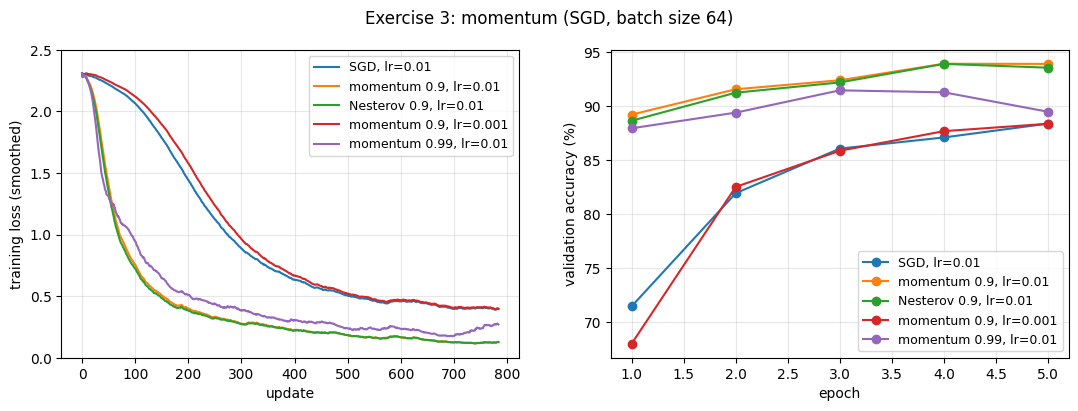


run                        effective lr  best val acc  final val acc  final train loss  diverged
SGD, lr=0.01                      0.010        88.40%         88.40%            0.3938  False
momentum 0.9, lr=0.01             0.100        93.95%         93.93%            0.1195  False
Nesterov 0.9, lr=0.01             0.100        93.93%         93.58%            0.1190  False
momentum 0.9, lr=0.001            0.010        88.38%         88.38%            0.3992  False
momentum 0.99, lr=0.01            1.000        91.48%         89.50%            0.2287  False


In [18]:
# Exercise 3: momentum
# Batch size 64, 5 epochs, first 10,000 training examples, same initial weights (make_model(seed=0))
# and same mini-batch order for every run. Only the optimizer settings change.

configs3 = {
    "SGD, lr=0.01":                    dict(lr=0.01),                                    # plain SGD
    "momentum 0.9, lr=0.01":           dict(lr=0.01, momentum=0.9),                      # step 1
    "Nesterov 0.9, lr=0.01":           dict(lr=0.01, momentum=0.9, nesterov=True),       # step 1
    "momentum 0.9, lr=0.001":          dict(lr=0.001, momentum=0.9),                     # step 2
    "momentum 0.99, lr=0.01":          dict(lr=0.01, momentum=0.99),                     # step 3
}

hists3 = {}
for name, cfg in configs3.items():
    print(f"=== {name} ===")
    model = make_model(seed=0)                                   # same starting weights every time
    optimizer = optim.SGD(model.parameters(), **cfg)
    loader = make_loader(batch_size=64, n_train=10_000)          # same data order every time
    hists3[name] = fit(model, optimizer, loader, epochs=5, verbose=False)

# step 4: all the runs on one figure
plot_history(hists3, "Exercise 3: momentum (SGD, batch size 64)")

# summary table; "effective lr" = lr / (1 - momentum) is the size of the steady-state step
print(f"\n{'run':26s} {'effective lr':>12s} {'best val acc':>13s} {'final val acc':>14s} {'final train loss':>17s}  diverged")
for (name, cfg), h in zip(configs3.items(), hists3.values()):
    eff = cfg["lr"] / (1 - cfg.get("momentum", 0.0))
    print(f"{name:26s} {eff:12.3f} {max(h['val_acc']):12.2f}% {h['val_acc'][-1]:13.2f}% {h['train_loss'][-1]:17.4f}  {h['diverged']}")

**Exercise 3: your observations and explanation.** *Write here.*

### 1. What was done

Five runs of the MLP with SGD, batch size 64, 5 epochs, on 10,000 training images, from the same initial weights and with the same mini-batch order. Only the optimizer settings change:

1. plain SGD, $\alpha = 0.01$ (the reference);
2. SGD with momentum 0.9, $\alpha = 0.01$;
3. SGD with Nesterov momentum 0.9, $\alpha = 0.01$;
4. SGD with momentum 0.9, $\alpha = 0.001$ (to compare with plain SGD at $\alpha = 0.01$);
5. SGD with momentum 0.99, $\alpha = 0.01$.

### 2. Background: what momentum is

**Plain SGD** forgets everything between two updates: each step depends only on the current mini-batch gradient $g_t$:

$$\theta \leftarrow \theta - \alpha\, g_t$$

**SGD with momentum** (PyTorch's version) keeps a **velocity** $v$, a running sum of past gradients that fade at rate $\mu$ (here $\mu = 0.9$ or $0.99$):

$$v \leftarrow \mu\, v + g_t, \qquad \theta \leftarrow \theta - \alpha\, v$$

Unrolling it, $v_t = g_t + \mu\, g_{t-1} + \mu^2 g_{t-2} + \dots$: the step is a weighted sum of the recent gradients. The picture is a **ball rolling down a hill**: it builds up speed in a direction that stays downhill, and it is not thrown around by every small bump.

Two consequences:

* **Directions where the gradient keeps the same sign** (for example the long axis of a valley): the contributions add up. In the steady state $v \approx g/(1-\mu)$, so the step is multiplied by $1/(1-\mu)$: **10 times** for $\mu = 0.9$ and **100 times** for $\mu = 0.99$. The ratio $\alpha/(1-\mu)$ is called the *effective learning rate*.
* **Directions where the gradient changes sign from one update to the next** (zigzag across a narrow valley, or mini-batch noise): the contributions cancel, so these oscillations are damped instead of amplified.

This is why momentum helps in a **ravine**, as in the toy problem of the follow-along: plain SGD zigzags across the narrow direction and crawls along the long one, while momentum cancels the zigzag and speeds up along the valley.

**Nesterov momentum** changes one detail. The standard method computes the gradient at the current point and then adds the velocity. Nesterov looks ahead: it uses the gradient at the place where the velocity is about to take us (PyTorch: $v \leftarrow \mu v + g_t$, then $\theta \leftarrow \theta - \alpha\,(g_t + \mu v)$). It is a correction in advance: if the ball is about to overshoot, it brakes a little earlier.

| Run | $\alpha$ | $\mu$ | Effective rate $\alpha/(1-\mu)$ |
|---|---|---|---|
| plain SGD | 0.01 | 0 | 0.01 |
| momentum 0.9 | 0.01 | 0.9 | 0.1 |
| Nesterov 0.9 | 0.01 | 0.9 | 0.1 |
| momentum 0.9 | 0.001 | 0.9 | 0.01 |
| momentum 0.99 | 0.01 | 0.99 | 1.0 |

### 3. Results

| Run | Effective rate | Best val acc | Final val acc | Final train loss |
|---|---|---|---|---|
| plain SGD, $\alpha=0.01$ | 0.01 | 88.40% | 88.40% | 0.3938 |
| momentum 0.9, $\alpha=0.01$ | 0.1 | **93.95%** | **93.93%** | 0.1195 |
| Nesterov 0.9, $\alpha=0.01$ | 0.1 | 93.93% | 93.58% | **0.1190** |
| momentum 0.9, $\alpha=0.001$ | 0.01 | 88.38% | 88.38% | 0.3992 |
| momentum 0.99, $\alpha=0.01$ | 1.0 | 91.48% | 89.50% | 0.2287 |

No run diverged (`diverged = False` for all).

**Reference from Exercise 1** (same data, batch size and epochs, *plain* SGD): $\alpha = 0.01$ gave 88.40%; $\alpha = 0.1$ gave a best of 93.62% but a final of 90.50% (final train loss 0.1164); $\alpha = 1$ failed (best 41.28%, final 18.92%, loss about 2.07).

### 4. Observations

1. **Momentum 0.9 with $\alpha = 0.01$ is far better than plain SGD with the same $\alpha$.** The final accuracy goes from 88.40% to 93.93% (+5.5 points) and the final training loss from 0.394 to 0.120 (3 times lower). The difference appears from the first epoch (89% against 71%). The loss curve falls to 0.5 in about 150 updates, while plain SGD needs about 450.
2. **It behaves like plain SGD with $\alpha = 0.1$, which is its effective rate, but more stable at the end.** Compare with Exercise 1 ($\alpha = 0.1$, plain SGD): the final training loss is almost the same (0.1195 against 0.1164) and the best accuracy is similar (93.95% against 93.62%). But the plain run ended at 90.50% (it dropped by 3 points in the last epoch), while momentum ends at 93.93%, with a validation curve that rises almost without dips.
3. **Nesterov (0.9, $\alpha=0.01$) is practically the same as standard momentum.** The two training curves lie on top of each other, the final losses are 0.1190 and 0.1195, and the best accuracies are 93.93% and 93.95%. The final accuracies differ by 0.35 points (93.58% against 93.93%, about 21 validation images), which is small and within the noise of a single seed. We cannot say that Nesterov is better or worse here.
4. **Momentum 0.9 with $\alpha = 0.001$ is equivalent to plain SGD with $\alpha = 0.01$.** The final accuracies are 88.38% and 88.40% (a difference of 0.02 points, one image), and the final losses 0.3992 and 0.3938. The loss curves are almost the same. The momentum run is slightly *slower at the very beginning* (epoch 1: 68% against 71.5%), since the velocity needs about 10 updates to build up, and the loss curve of the momentum run stays a little above that of plain SGD during the first 400 updates.
5. **Momentum 0.99 with $\alpha = 0.01$: very fast start, then it stalls and gets worse.**
   * In the first ~50 updates its loss falls faster than all the others (it has the largest effective rate).
   * Then it slows down: at update 300 its loss is about 0.4, against 0.28 for momentum 0.9, and it stays above that curve for the rest of the training.
   * Its loss **increases again** after update 700 (from about 0.18 to 0.27), and its validation accuracy rises to **91.48% at epoch 3**, then falls: 91.3% at epoch 4 and **89.50%** at epoch 5.
   * It ends 4.4 points below momentum 0.9 (93.93%), although it is above plain SGD (88.40%). It did not diverge, but it is clearly unstable.

### 5. Explanations

* **Momentum multiplies the useful step.** When successive gradients point in the same direction, the velocity builds up to $g/(1-\mu)$. With $\mu = 0.9$ the step along a consistent direction is 10 times larger, so momentum 0.9 with $\alpha = 0.01$ moves at about the speed of plain SGD with $\alpha = 0.1$. That is exactly what runs 2 and 4 show: **the $\alpha/(1-\mu)$ rule predicts the results** (effective rate 0.1 gives 93.9%; effective rate 0.01 gives 88.4%, with both a plain and a momentum run, and with the same final accuracy).
* **Why momentum 0.9 at the same effective rate is more stable than plain SGD with $\alpha=0.1$.** With plain SGD at 0.1, each step follows its own noisy mini-batch gradient, so the parameters keep bouncing (the last-epoch drop to 90.50% in Exercise 1). With momentum, the velocity is an *average* of about the last 10 gradients: the random parts of the mini-batch gradients partly cancel each other, and only the consistent part remains. The result is an update with the same size but less noise.
* **Why momentum 0.99 does not fail like plain SGD at $\alpha = 1$ (a thing I did not expect).** The effective rate of 1.0 only applies when the gradients are consistent. Noisy gradients and oscillating components cancel in the velocity, so the real step is much smaller than $\alpha/(1-\mu)$ in most directions, and plain SGD with $\alpha = 1$ takes the full unaveraged step in every direction. This explains why momentum 0.99 survives (no divergence, 91.5% at best), while plain SGD at 1 failed (41% at best). It is also why the effective rate must be used as a guide, not as an exact equivalence.
* **Why momentum 0.99 still gets worse.** A $\mu = 0.99$ velocity remembers about $1/(1-0.99) = 100$ updates, i.e. a third of an epoch of the 157 updates per epoch. The ball is very heavy:
  * *at the start* it accelerates very fast along the main direction (the fast first 50 updates);
  * *near the minimum* it cannot stop in time: it overshoots, climbs the opposite slope, and comes back, so the loss oscillates around the valley with a large amplitude instead of settling. This is why the curve stays above momentum 0.9 from update 100 and why it **rises again** near the end (update 700+), and why the accuracy peaks at epoch 3 (91.5%) and then decreases;
  * in addition, the effective step of 1.0 is large, and the noise that is not averaged out is amplified.
  Using $\mu = 0.99$ would require a much smaller $\alpha$ (for example 0.001), or a learning rate that decreases during training (Exercise 5).
* **The learning rate and the momentum are one decision, not two.** The effective rate $\alpha/(1-\mu)$ controls how fast we go: going from $\mu = 0.9$ to $0.99$ with the same $\alpha$ multiplies it by 10 and made the result worse by 4.4 points, and going from $\alpha = 0.01$ to 0.001 at $\mu = 0.9$ divided it by 10 and made the result worse by 5.5 points. The best of the five runs is the intermediate one (0.1).
* **Why Nesterov changes almost nothing here.** The look-ahead correction is proportional to $\alpha\mu$, and with $\alpha = 0.01$ it is small, so the two trajectories remain close. Its benefit is usually visible when the momentum is large and the surface is sharp, and it was not visible with this setup.

### 6. Conclusion

* Momentum smooths the update direction and accelerates descent along consistent directions, with an effective step $\alpha/(1-\mu)$.
* **Momentum 0.9 with $\alpha = 0.01$ was the best choice** (93.93% final, loss 0.12), as good as plain SGD with $\alpha = 0.1$ but more stable at the end.
* **Nesterov** gave no measurable gain (differences within the noise).
* **Momentum 0.9 with $\alpha = 0.001$** gave the same result as plain SGD with $\alpha = 0.01$ (88.38% against 88.40%): reducing $\alpha$ by 10 cancels the effect of momentum.
* **Momentum 0.99** with $\alpha = 0.01$ was too heavy: fast at first, but with oscillations and a loss that increased again at the end (final 89.50%).
* Therefore $\mu = 0.9$ is a good default, and when $\mu$ increases, $\alpha$ must decrease. The next exercise compares optimizers that adapt the step automatically, and the one after studies decreasing the learning rate during training.

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

=== SGD, lr = 0.1 ===
=== SGD, lr = 0.01 ===
=== SGD, lr = 0.001 ===
=== SGD, lr = 0.0001 ===
=== SGD momentum 0.9, lr = 0.1 ===
=== SGD momentum 0.9, lr = 0.01 ===
=== SGD momentum 0.9, lr = 0.001 ===
=== SGD momentum 0.9, lr = 0.0001 ===
=== Adagrad, lr = 0.1 ===
=== Adagrad, lr = 0.01 ===
=== Adagrad, lr = 0.001 ===
=== Adagrad, lr = 0.0001 ===
=== RMSprop, lr = 0.1 ===
=== RMSprop, lr = 0.01 ===
=== RMSprop, lr = 0.001 ===
=== RMSprop, lr = 0.0001 ===
=== Adam, lr = 0.1 ===
=== Adam, lr = 0.01 ===
=== Adam, lr = 0.001 ===
=== Adam, lr = 0.0001 ===
=== AdamW, lr = 0.1 ===
=== AdamW, lr = 0.01 ===
=== AdamW, lr = 0.001 ===
=== AdamW, lr = 0.0001 ===

Best validation accuracy (%)   [* = diverged]
optimizer                lr=0.1      lr=0.01     lr=0.001    lr=0.0001
SGD                      93.62        88.40        53.40         9.88 
SGD momentum 0.9         92.75        93.95        88.38        52.55 
Adagrad                  92.35        93.93        89.15        67.98 
RMSprop  

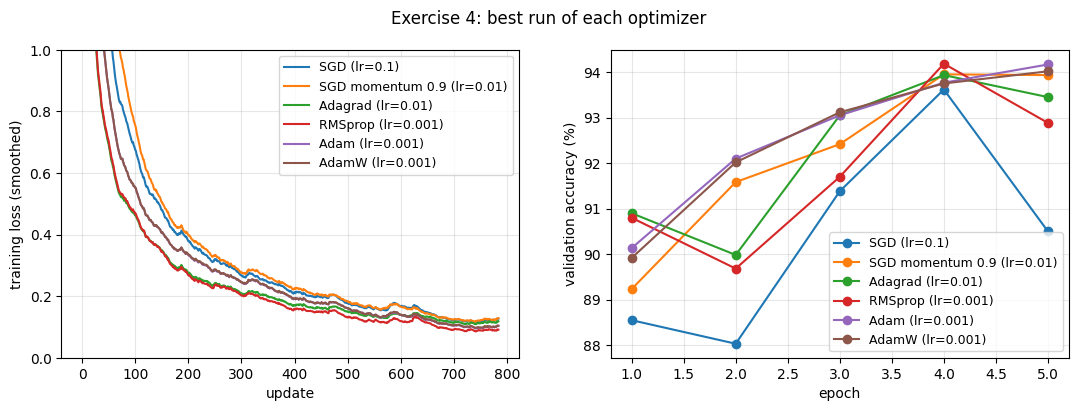

In [19]:
# Exercise 4: optimizers and their learning rates
# Batch size 64, 5 epochs, first 10,000 training examples, same initial weights (make_model(seed=0))
# and same mini-batch order for every run. 6 optimizers x 4 learning rates = 24 runs.

lrs4 = [1e-1, 1e-2, 1e-3, 1e-4]

optimizers4 = {
    "SGD":              lambda p, lr: optim.SGD(p, lr=lr),
    "SGD momentum 0.9": lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9),
    "Adagrad":          lambda p, lr: optim.Adagrad(p, lr=lr),
    "RMSprop":          lambda p, lr: optim.RMSprop(p, lr=lr),
    "Adam":             lambda p, lr: optim.Adam(p, lr=lr),
    "AdamW":            lambda p, lr: optim.AdamW(p, lr=lr),
}

hists4 = {}                                   # hists4[(optimizer name, lr)] = history
for opt_name, make_opt in optimizers4.items():
    for lr in lrs4:
        print(f"=== {opt_name}, lr = {lr} ===")
        model = make_model(seed=0)                                   # same starting weights every time
        optimizer = make_opt(model.parameters(), lr)
        loader = make_loader(batch_size=64, n_train=10_000)          # same data order every time
        hists4[(opt_name, lr)] = fit(model, optimizer, loader, epochs=5, verbose=False)

# 2. table of the best validation accuracy: one row per optimizer, one column per learning rate
# (a "*" after a number means that the run diverged: the loss became nan or inf)
print("\nBest validation accuracy (%)   [* = diverged]")
print(f"{'optimizer':18s}" + "".join(f"{('lr=' + str(lr)):>13s}" for lr in lrs4))
best_run = {}                                 # best (lr, history) of each optimizer
for opt_name in optimizers4:
    row = f"{opt_name:18s}"
    for lr in lrs4:
        h = hists4[(opt_name, lr)]
        acc = max(h["val_acc"])
        row += f"{acc:12.2f}{'*' if h['diverged'] else ' '}"
        if opt_name not in best_run or acc > best_run[opt_name][0]:
            best_run[opt_name] = (acc, lr)
    print(row)

print("\nBest learning rate of each optimizer:")
for opt_name, (acc, lr) in best_run.items():
    print(f"{opt_name:18s} lr = {lr:<7} best val acc {acc:.2f}%")

# 3. the best run of each optimizer on one figure
best_hists = {f"{n} (lr={lr})": hists4[(n, lr)] for n, (acc, lr) in best_run.items()}
plot_history(best_hists, "Exercise 4: best run of each optimizer", ylim=(0, 1.0))

**Exercise 4: your observations and explanation.** *Write here.*

### 1. What was done

Six optimizers were trained with four learning rates each, $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$: 24 runs in total. Every run uses the same MLP initial weights, the same 10,000 training images in the same mini-batch order, batch size 64 and 5 epochs. **Only the optimizer and its learning rate change.** The table gives the best validation accuracy (over the 5 epochs) of each run, and the figure shows the best run of each optimizer.

### 2. Background: what each optimizer does

Notation: $g$ is the mini-batch gradient of one parameter, $\theta$ the parameter, $\alpha$ the learning rate, $\epsilon$ a tiny number (about $10^{-8}$) that avoids dividing by zero.

**SGD:** $\theta \leftarrow \theta - \alpha\, g$. The same learning rate is used for every parameter, and the step is proportional to the gradient.

**SGD with momentum 0.9:** $v \leftarrow 0.9\,v + g$, $\theta \leftarrow \theta - \alpha\, v$. It averages the recent gradients (about the last 10), so the effective step along consistent directions is $\alpha/(1-0.9) = 10\,\alpha$ (Exercise 3).

**The idea of the next four optimizers: adaptive learning rates.** In plain SGD, the gradients of different parameters have very different sizes (for example, a weight connected to a pixel that is almost always zero has a tiny gradient), but all of them are multiplied by the same $\alpha$. The adaptive methods **divide the gradient by an estimate of its own typical size**, so that every parameter moves by a comparable amount.

* **Adagrad** accumulates the *sum of all past squared gradients*:
  $$G \leftarrow G + g^2, \qquad \theta \leftarrow \theta - \alpha\,\frac{g}{\sqrt{G}+\epsilon}$$
  Each parameter gets its own rate $\alpha/\sqrt{G}$. Since $G$ only grows, **the effective step can only decrease** during training: it is large at the start (the first update moves every weight by exactly $\alpha$, because $g/\sqrt{g^2} = \pm1$) and becomes smaller and smaller (roughly like $1/\sqrt{t}$). It is a built-in learning-rate schedule. The weakness: later the steps may become too small and learning slows down.
* **RMSprop** replaces the sum by a **moving average** of the squared gradients (it forgets the old ones; PyTorch's default decay is 0.99):
  $$s \leftarrow 0.99\,s + 0.01\,g^2, \qquad \theta \leftarrow \theta - \alpha\,\frac{g}{\sqrt{s}+\epsilon}$$
  The step stays of order $\alpha$ during the whole training and does not die out. (A detail: $s$ starts at 0 and is not corrected, so in the first updates $\sqrt{s}$ is much smaller than the true gradient size, and the first steps are up to **10 times larger than $\alpha$**; this fades after about 100 updates.)
* **Adam** = momentum + RMSprop. It keeps a moving average of the gradient $m$ (the direction, like momentum, $\beta_1 = 0.9$) and of the squared gradient $v$ (the scale, like RMSprop, $\beta_2 = 0.999$), **corrects their bias** at the start of training (so there is no burst at the beginning), and moves by
  $$\theta \leftarrow \theta - \alpha\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$$
  The ratio $\hat m/\sqrt{\hat v}$ has size of order 1 (at most about 1), so **each parameter moves by about $\alpha$ per update**, whatever the size of its gradient.
* **AdamW** is Adam with a different way of applying *weight decay* (a penalty that pulls the weights towards 0). In Adam, an L2 penalty is added to the gradient and is then rescaled by the adaptive division; AdamW applies the decay **directly on the weights, separately from the gradient step**: $\theta \leftarrow \theta - \alpha\left(\hat m/(\sqrt{\hat v}+\epsilon) + \lambda\,\theta\right)$, with PyTorch's default $\lambda = 0.01$. For small $\alpha$ and 785 updates the decay term $\alpha\lambda\theta$ is tiny, so AdamW is expected to behave like Adam.

**Why the best learning rate differs between optimizers.** For **SGD**, the step is $\alpha \times$ (the gradient), so $\alpha$ is a conversion factor that depends on the size of the gradients. For **Adam and RMSprop**, the step is about $\alpha$ itself: $\alpha$ is directly "the distance each weight moves per update". The weights of this network are of order 0.03 to 0.1, so a move of 0.1 per update is enormous, and 0.001 is reasonable. The good ranges are therefore on different scales.

### 3. Results (best validation accuracy, %)

None of the 24 runs diverged to `nan` or `inf` (no `*` in the table), but several runs *failed to train* (accuracy far below the others).

| Optimizer | $\alpha=10^{-1}$ | $\alpha=10^{-2}$ | $\alpha=10^{-3}$ | $\alpha=10^{-4}$ | best $\alpha$ | best acc |
|---|---|---|---|---|---|---|
| SGD | **93.62** | 88.40 | 53.40 | 9.88 | $10^{-1}$ | 93.62 |
| SGD momentum 0.9 | 92.75 | **93.95** | 88.38 | 52.55 | $10^{-2}$ | 93.95 |
| Adagrad | 92.35 | **93.93** | 89.15 | 67.98 | $10^{-2}$ | 93.93 |
| RMSprop | 22.07 | 90.07 | **94.18** | 89.92 | $10^{-3}$ | **94.18** |
| Adam | 27.10 | 92.45 | **94.17** | 90.03 | $10^{-3}$ | 94.17 |
| AdamW | 36.60 | 92.78 | **94.02** | 90.05 | $10^{-3}$ | 94.02 |

**Consistency checks with the previous exercises** (same setup): the SGD row at $10^{-1}, 10^{-2}, 10^{-3}$ (93.62, 88.40, 53.40) is exactly Exercise 1, and the momentum row at $10^{-2}$ and $10^{-3}$ (93.95, 88.38) is exactly Exercise 3. This confirms that the pipeline is the same.

### 4. Observations

1. **Each optimizer has its own good range, and the ranges are very different.**
   * **SGD** needs a large rate: the best is $10^{-1}$ (93.62%), and the accuracy falls quickly when it decreases: 88.40% at $10^{-2}$, 53.40% at $10^{-3}$, and **9.88% at $10^{-4}$, which is random guessing** for 10 classes (the model has not moved). (The best value is at the edge of the grid, but Exercise 1 showed that $\alpha = 0.3$ gives the same 93.3% and $\alpha = 1$ fails, so there is nothing better above.)
   * **SGD with momentum** is best at $10^{-2}$ (93.95%), a rate 10 times smaller than for SGD, and a shift of the whole row by one column: 92.75 / 93.95 / 88.38 / 52.55, compared with SGD's 93.62 / 88.40 / 53.40 / 9.88.
   * **Adagrad** is best at $10^{-2}$ (93.93%) and is the only adaptive method that works well at $10^{-1}$ (92.35%).
   * **RMSprop, Adam and AdamW** are best at **$10^{-3}$** (94.18%, 94.17%, 94.02%) and **fail at $10^{-1}$**: 22.07%, 27.10% and 36.60%, far below random-guessing-plus-learning levels of the other optimizers.
2. **Momentum behaves as if its learning rate were multiplied by 10.** The momentum row is the SGD row shifted by one column: momentum at $10^{-3}$ (88.38%) equals SGD at $10^{-2}$ (88.40%); momentum at $10^{-4}$ (52.55%) equals SGD at $10^{-3}$ (53.40%); momentum at $10^{-2}$ (93.95%) equals SGD at $10^{-1}$ (93.62%). The effective rate $\alpha/(1-\mu)$ of Exercise 3 predicts this shift. **The exception is the largest rate:** momentum at $10^{-1}$ has an effective rate of 1.0, where plain SGD failed in Exercise 1 (41.28%), but it reached 92.75%. It did not fail, only lost 1.2 points relative to its best (as for momentum 0.99 in Exercise 3).
3. **The adaptive methods tolerate a small learning rate much better.** At $\alpha = 10^{-4}$: Adam 90.03%, AdamW 90.05%, RMSprop 89.92%, Adagrad 67.98%, SGD with momentum 52.55%, SGD 9.88%. After the same 5 epochs and with the same tiny $\alpha$, the adaptive methods have learned almost as much as at their best rate, while SGD has not moved.
4. **Tolerance, counted with a simple criterion.** Number of the four learning rates that gave at least 90%: SGD 1 ($10^{-1}$), momentum 2, Adagrad 2 (89.15% at $10^{-3}$ just misses), RMSprop 2 (89.92% at $10^{-4}$ just misses), **Adam 3, AdamW 3**. Adam and AdamW are the most tolerant to a wrong choice of $\alpha$; SGD is the least.
5. **The best runs are all close to each other.** The best accuracies are 94.18 (RMSprop), 94.17 (Adam), 94.02 (AdamW), 93.95 (momentum), 93.93 (Adagrad), 93.62 (SGD): a **range of only 0.56 points**, about 34 of the 6,000 validation images. The statistical uncertainty of one accuracy is about 0.3 points, and this is one seed per run, so **I cannot rank these six optimizers**; with a well-tuned rate they are equivalent in this experiment.
6. **Adam and AdamW are almost identical when training works well, and not when it fails.** At $10^{-3}$ (94.17 vs 94.02) and $10^{-4}$ (90.03 vs 90.05) they agree within 0.15 points, and the two curves overlap in the figure (the purple Adam curve is hidden behind the brown AdamW one). At $10^{-2}$ the gap is 0.33 points, and at $10^{-1}$ it is 9.5 points (27.10 vs 36.60).
7. **The figure of the best runs (values read from the plot, approximate).**
   * *Speed of the training loss:* RMSprop and Adagrad descend fastest (loss about 0.47 after 100 updates), then Adam and AdamW (about 0.57), then SGD and momentum (about 0.7). At the end, RMSprop has the lowest loss (about 0.09), Adam/AdamW about 0.10, Adagrad about 0.115, SGD and momentum about 0.12.
   * *Stability of the validation accuracy:* **Adam, AdamW and momentum rise almost steadily** and finish at their best level (about 94.15%, 94.0% and 93.95%). **SGD, RMSprop and Adagrad peak at epoch 4 and then drop** in epoch 5: SGD from 93.62% to 90.50% (the same dip seen in Exercise 1), RMSprop from 94.18% to about 92.9%, Adagrad from 93.93% to about 93.5%. So by the **final** accuracy the order is Adam > AdamW > momentum > Adagrad > RMSprop > SGD, while by the best accuracy (the table) RMSprop is first. The "best over epochs" number is optimistic for the noisy runs.

### 5. Explanations

* **Why the same $\alpha$ means different things.** SGD's step is $\alpha\,g$; Adam's step is about $\alpha\, g/\sqrt{\overline{g^2}} \approx \pm\alpha$. For SGD, $\alpha$ converts a gradient into a step; for Adam, it is the distance a weight moves in one update. That is why SGD works at $10^{-1}$ and Adam at $10^{-3}$, and why a learning rate found for one optimizer cannot be reused for another. It must be searched **for each optimizer separately**, on a log grid.
* **Why SGD does not move at $10^{-4}$ but Adam does.** For SGD the step is $\alpha\,g$, and the gradient is itself small (the loss is only about 2.3 at the start, and then decreases), so the step is $10^{-4} \times$ small: 785 updates cannot change anything (9.88%). Adam divides $g$ by its own size, so the step is $\approx 10^{-4}$ per weight regardless of how small $g$ is: 785 updates move each weight by up to about 0.08, which is enough to learn (90%).
* **Why Adam/RMSprop/AdamW fail at $10^{-1}$.** Each weight moves by about 0.1 in every update, in the direction of the sign of a noisy gradient. That is larger than the weights themselves, so the output of the network is thrown around and the loss never settles (22 to 37%). It is the same phenomenon as SGD with $\alpha = 1$ in Exercise 1.
* **Why Adagrad survives $\alpha = 0.1$ while Adam does not.** The first Adagrad update is as large as Adam's (about 0.1 per weight), but then $G$ accumulates, so the step falls like $1/\sqrt{t}$: after 100 updates it is about 0.01, after 785 about 0.004. Adagrad **corrects a too large $\alpha$ by itself** within a few dozen updates, which is why it still reaches 92.35%. Adam's step stays about $\alpha = 0.1$ for the whole run. The same decay is the weakness at small rates: at $10^{-3}$ and $10^{-4}$ the step shrinks to almost nothing (89.15% and 67.98%, compared with 94.17% and 90.03% for Adam). This ties into Exercise 5: Adagrad has a schedule built in, and a schedule helps when $\alpha$ is large.
* **Why momentum survives an effective rate of 1.** The effective rate $\alpha/(1-\mu)$ only applies to a consistent gradient direction; the noisy and oscillating components cancel in the velocity (Exercise 3). Plain SGD at $\alpha = 1$ takes the full unaveraged step in every direction, so it fails. This is an explanation consistent with both experiments (momentum 0.99 at $10^{-2}$ in Exercise 3, and momentum 0.9 at $10^{-1}$ here), not a proof.
* **Why RMSprop is the least tolerant of the adaptive methods (a plausible reason).** Its first steps are up to 10 times larger than $\alpha$ (no bias correction), and it has no momentum to average out noise. This fits two observations: at $10^{-2}$ RMSprop (90.07%) is clearly behind Adam (92.45%) and AdamW (92.78%), and its accuracy at the best rate is noisy (the drop from 94.18% to about 92.9% in the last epoch). Despite that, it has the lowest training loss.
* **Why Adam and AdamW differ at large $\alpha$ but not at small $\alpha$.** The weight-decay term of AdamW is tiny, so when the training is well behaved the two follow almost the same path. When $\alpha$ is too large the training is chaotic: a tiny difference between the two updates is amplified and the runs end at different (equally bad) places, so the gap of 9.5 points at $10^{-1}$ is the sensitivity of a failing run, not an effect of weight decay. I do not claim that AdamW is better at large rates.
* **Adaptive methods are not magic.** At its best rate, SGD with momentum is within 0.2 points of Adam (93.95 vs 94.17) on this small, well-scaled problem (normalized inputs, a small MLP), so the difference is within noise. The advantage of the adaptive methods here is **robustness**: Adam works well at $10^{-3}$ and still well at $10^{-2}$ and $10^{-4}$, whereas the SGD rate has to be found within a narrow window (one value out of four).
* **Caution about the comparison.** One run per setting, only 5 epochs, and a 6,000-image validation set. Runs that are within about half a point should be considered equal; gaps of several points (wrong learning rate) are reliable. The small rates are still improving after 5 epochs (for example SGD with momentum at $10^{-4}$) and could catch up with more epochs, so the table measures what is reached **in 5 epochs**. Finally, "best validation accuracy" takes the maximum over epochs and favors noisy runs; the final accuracy is a fairer measure of the model we would keep.

### 6. Conclusion

The optimizer and its learning rate must be chosen together, because the meaning of $\alpha$ depends on the optimizer:

* **SGD:** best at $\alpha = 10^{-1}$ (93.62%), and the most sensitive (9.88% at $10^{-4}$).
* **SGD with momentum:** best at $10^{-2}$ (93.95%), the SGD row shifted by one column (effective rate $10\,\alpha$).
* **Adagrad:** best at $10^{-2}$ (93.93%); its steps shrink during training, which protects it at large $\alpha$ but slows it at small $\alpha$.
* **RMSprop, Adam, AdamW:** their step is about $\alpha$, so the good range is much smaller: best at $10^{-3}$ (94.18%, 94.17%, 94.02%), and failing at $10^{-1}$ (22 to 37%).
* **Differences between the optimizers at their best learning rate are small** (0.56 points between the best and the worst) and not significant with one seed. **Adam and AdamW are the most robust** (three of four rates above 90%, steady validation curves, best final accuracy), so **Adam with $\alpha = 10^{-3}$ is a good default** for a new problem, while SGD with momentum at $10^{-2}$ is a strong alternative once its rate is tuned.

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

=== constant 0.05 ===
best val acc 95.88% | final val acc 94.33% | final train loss 0.0446 | final val loss 0.3300
=== StepLR (step 3, gamma 0.3) ===
best val acc 95.80% | final val acc 95.78% | final train loss 0.0082 | final val loss 0.1773
=== ExponentialLR (gamma 0.7) ===
best val acc 95.58% | final val acc 95.53% | final train loss 0.0107 | final val loss 0.1783
=== CosineAnnealingLR (T_max 10) ===
best val acc 96.07% | final val acc 96.07% | final train loss 0.0026 | final val loss 0.1859
=== StepLR (step 1, gamma 0.1) ===
best val acc 93.70% | final val acc 93.70% | final train loss 0.1166 | final val loss 0.2120


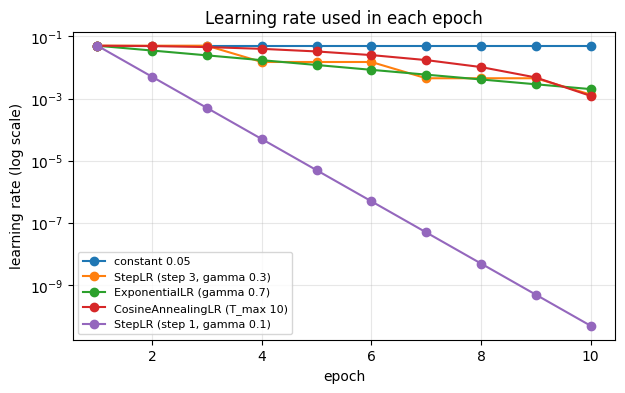

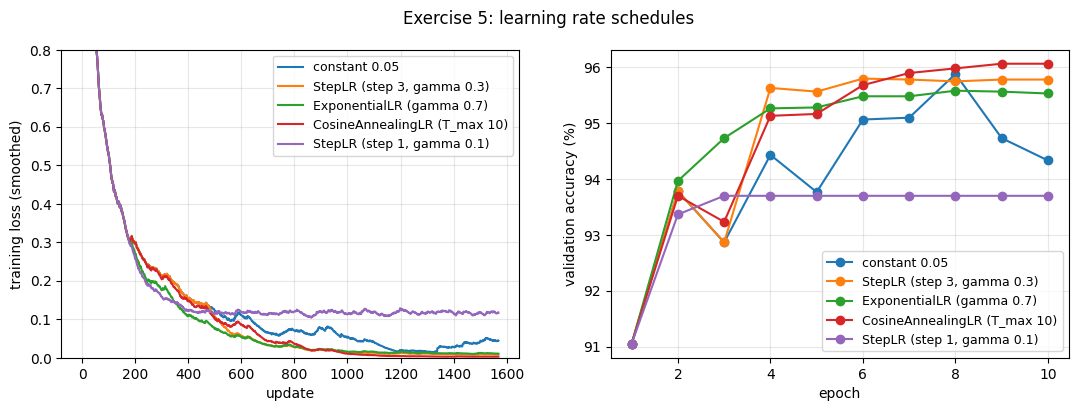


schedule                          lr first   lr last  best val acc  final train loss
constant 0.05                     5.00e-02  5.00e-02        95.88%            0.0446
StepLR (step 3, gamma 0.3)        5.00e-02  1.35e-03        95.80%            0.0082
ExponentialLR (gamma 0.7)         5.00e-02  2.02e-03        95.58%            0.0107
CosineAnnealingLR (T_max 10)      5.00e-02  1.22e-03        96.07%            0.0026
StepLR (step 1, gamma 0.1)        5.00e-02  5.00e-11        93.70%            0.1166


In [20]:
# Exercise 5: learning rate schedules
# Every run: SGD(lr=0.05, momentum=0.9), batch size 64, 10 epochs, first 10,000 training examples,
# same initial weights (make_model(seed=0)) and same mini-batch order (make_loader seed=0).
# Only the learning rate schedule changes.

EPOCHS = 10

# each entry: a function that takes the optimizer and returns a scheduler (None = constant lr)
schedules = {
    "constant 0.05":                  lambda opt: None,
    "StepLR (step 3, gamma 0.3)":     lambda opt: optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.3),
    "ExponentialLR (gamma 0.7)":      lambda opt: optim.lr_scheduler.ExponentialLR(opt, gamma=0.7),
    "CosineAnnealingLR (T_max 10)":   lambda opt: optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10),
    "StepLR (step 1, gamma 0.1)":     lambda opt: optim.lr_scheduler.StepLR(opt, step_size=1, gamma=0.1),
}

hists5 = {}   # empty box
for name, make_sched in schedules.items():
    print(f"=== {name} ===")
    model = make_model(seed=0)                                    # same initial weights for every run
    optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    scheduler = make_sched(optimizer)                             # must be created AFTER the optimizer
    loader = make_loader(batch_size=64, n_train=10_000)           # same mini-batch order for every run
    hists5[name] = fit(model, optimizer, loader, epochs=EPOCHS, scheduler=scheduler, verbose=False)
    h = hists5[name]
    print(f"best val acc {max(h['val_acc']):.2f}% | final val acc {h['val_acc'][-1]:.2f}% | "
          f"final train loss {h['train_loss'][-1]:.4f} | final val loss {h['val_loss'][-1]:.4f}")

# 2. learning rate of each run, per epoch (log scale)
plt.figure(figsize=(7, 4))
for name, h in hists5.items():
    plt.plot(range(1, len(h["lr"]) + 1), h["lr"], "o-", label=name)
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("learning rate (log scale)")
plt.title("Learning rate used in each epoch")
plt.grid(alpha=0.3, which="both"); plt.legend(fontsize=8); plt.show()

# 3. training loss (smoothed) and validation accuracy of the five runs
plot_history(hists5, "Exercise 5: learning rate schedules", ylim=(0, 0.8))

# summary table
print(f"\n{'schedule':32s} {'lr first':>9s} {'lr last':>9s} {'best val acc':>13s} {'final train loss':>17s}")
for name, h in hists5.items():
    print(f"{name:32s} {h['lr'][0]:9.2e} {h['lr'][-1]:9.2e} {max(h['val_acc']):12.2f}% {h['train_loss'][-1]:17.4f}")

**Exercise 5: your observations and explanation.** *Write here.*

### 1. What was done

Five runs were trained with exactly the same setup: the same initial weights (`make_model(seed=0)`), the same 10,000 training images in the same mini-batch order, SGD with momentum 0.9, batch size 64, initial learning rate $\alpha_0 = 0.05$, and 10 epochs (157 updates per epoch, 1,570 updates in total). **The only difference is the learning-rate schedule.** `fit` calls `scheduler.step()` once per epoch, so the learning rate is constant inside an epoch and changes only between epochs. `history["lr"]` records the rate used in each epoch.

This is a controlled experiment, and the figures confirm it. In epoch 1 all five runs use the same rate (0.05), and their training-loss curves are on top of each other until about update 157, and all five have exactly the same validation accuracy after epoch 1 (about 91.05%). The curves separate only when the schedules start to give different rates.

### 2. Why change the learning rate during training?

The learning rate $\alpha$ is the size of the step in $\theta \leftarrow \theta - \alpha \cdot (\text{update direction})$. A large and a small $\alpha$ have opposite advantages:

* **Large $\alpha$**: fast progress at the beginning, when the parameters are far from a good solution. But the gradient of a mini-batch is only a **noisy** estimate of the true gradient. With a large step, this noise moves the parameters randomly, so they keep bouncing around the minimum instead of settling in it (a "noise floor" that grows with $\alpha$).
* **Small $\alpha$**: precise steps that let the parameters settle in the bottom of the valley, but slow progress if used from the start.

A schedule combines both: **large first (move fast), small later (remove the noise)**. Here the optimizer uses momentum 0.9. The velocity adds up about $1/(1-0.9) = 10$ successive gradients, so the *effective* step is about $0.05 \times 10 = 0.5$. This is large, so we expect the constant run to be noisy.

### 3. The five schedules

With $t = 0, 1, \dots, 9$ the number of epochs already completed (epoch number = $t + 1$):

| Schedule | Formula | Learning rate in epochs 1, 2, ..., 10 |
|---|---|---|
| constant | $\alpha_t = 0.05$ | 0.05 in every epoch |
| StepLR (step 3, gamma 0.3) | $0.05 \cdot 0.3^{\lfloor t/3 \rfloor}$ | 0.05 (epochs 1-3), 0.015 (4-6), 0.0045 (7-9), 0.00135 (10) |
| ExponentialLR (gamma 0.7) | $0.05 \cdot 0.7^{t}$ | 0.05, 0.035, 0.0245, 0.0172, 0.0120, 0.0084, 0.0059, 0.0041, 0.0029, 0.0020 |
| CosineAnnealingLR (T_max 10) | $\frac{0.05}{2}\left(1 + \cos\frac{\pi t}{10}\right)$ | 0.050, 0.049, 0.045, 0.040, 0.033, 0.025, 0.017, 0.010, 0.0048, 0.0012 |
| StepLR (step 1, gamma 0.1) | $0.05 \cdot 0.1^{t}$ | 0.05, 0.005, 0.0005, $5\cdot10^{-5}$, ..., $5\cdot10^{-11}$ |

On the learning-rate figure (log scale) this is what we see: constant is a horizontal line. ExponentialLR and "step 1" are straight lines going down (a constant factor per epoch gives a straight line on a log axis), "step 1" much steeper (down to $10^{-10}$, far below the other curves). StepLR (step 3) is a staircase with two steps visible at epochs 4 and 7 (and a small one at epoch 10). Cosine stays near 0.05 for the first 3 epochs, then goes down faster, and ends close to the others at about $10^{-3}$.

### 4. Results

| Schedule | best val acc | final val acc | final train loss | final val loss |
|---|---|---|---|---|
| constant 0.05 | 95.88% | **94.33%** | 0.0446 | **0.3300** |
| StepLR (step 3, gamma 0.3) | 95.80% | 95.78% | 0.0082 | 0.1773 |
| ExponentialLR (gamma 0.7) | 95.58% | 95.53% | 0.0107 | 0.1783 |
| CosineAnnealingLR (T_max 10) | **96.07%** | **96.07%** | **0.0026** | 0.1859 |
| StepLR (step 1, gamma 0.1) | 93.70% | 93.70% | 0.1166 | 0.2120 |

### 5. Observations, run by run

1. **Constant 0.05: noisy and unstable at the end.** Its validation accuracy goes up and down: 94.4 → 93.8 → 95.05 → 95.1 → **95.88 (epoch 8)** → 94.7 → **94.33 (epoch 10)**. Its smoothed training loss reaches about 0.015 near update 1200, then **goes back up** to about 0.045 at the end, and its final validation loss (0.33) is almost twice that of the decayed runs (about 0.18). Its *best* accuracy (95.88%) is as high as the schedules', but it was reached by chance at epoch 8: one epoch later the accuracy has fallen by more than 1 point. Its *final* accuracy is the worst of the four runs that keep learning.
2. **StepLR (step 3, gamma 0.3).** It is identical to the constant run during epochs 1-3 (same rate), with the same dip at epoch 3 (about 92.9%). **Right after the first decay (epoch 4), the accuracy jumps to about 95.6%** and the training loss falls away from the constant curve (around update 470, the end of epoch 3). After that the curve is flat and stable (95.75-95.8%). Final: 95.78%.
3. **ExponentialLR (gamma 0.7).** Its rate decreases from the second epoch, so it is the best of the schedules in epochs 2-3 (93.97%, then 94.7%) and then rises smoothly with no dip. But it stops improving early (about 95.5% from epoch 6 on) and ends at 95.53% with a training loss (0.0107) higher than StepLR (step 3) and cosine.
4. **CosineAnnealingLR (T_max 10).** It keeps a high rate longer, so in the first epochs it is not better than the others (it also dips at epoch 3, to 93.25%). But its accuracy keeps **increasing steadily until the end** (95.7 → 95.9 → 96.0 → 96.07%) and it reaches the **best final accuracy and by far the lowest training loss (0.0026)**.
5. **StepLR (step 1, gamma 0.1): decays too early.** The rate is 10 times smaller after the first epoch. The accuracy still improves a little in epochs 2-3 (93.4% → 93.7%), then stays **exactly at 93.70% from epoch 3 to 10**, and the training loss is a **flat line at about 0.115** from about update 300. It finishes with the **lowest accuracy (93.70%) and a training loss (0.1166) 3 to 40 times higher than the other runs**.

### 6. Explanations

* **Why the constant run is unstable.** With an effective step of about 0.5, each update is dominated by the noise of its mini-batch. Near a minimum this noise pushes the parameters out of the valley again and again, so the loss and accuracy fluctuate: the model at the end of epoch 8 and the model at the end of epoch 10 are almost the same size of distance from the minimum, but one is lucky and one is not. This is why the training loss increases again after update 1300 and why the validation accuracy loses 1.5 points in two epochs. The best-accuracy number hides this problem, and the **final** accuracy and the validation loss show it.
* **Why decaying fixes it.** When $\alpha$ decreases, the random part of each step becomes smaller, so the parameters stop bouncing and move into the bottom of the valley. We see exactly this in the three good schedules: the loss goes *down again* after the rate drops (see the jump of StepLR (step 3) at epoch 4), the curves become smooth, and the accuracy stays at its level from one epoch to the next (the difference between best and final accuracy is at most 0.05 points, compared with 1.55 points for the constant run). This is the same problem seen in the follow-along with batch size 1, which reached the minimum region quickly but never settled and needed a decaying rate.
* **Why cosine reached the lowest training loss.** The total amount of learning rate used during the 10 epochs (the sum of the ten rates) is about **0.275 for cosine**, **0.210 for StepLR (step 3)** and **0.162 for ExponentialLR**. The order of the final training losses (0.0026 < 0.0082 < 0.0107) is the same. This is consistent with the following explanation: cosine keeps the large, fast rate for the first half of training (a lot of progress) and still ends with a very small rate (settling), while exponential decay lowers the rate from the very first epochs, so it has less total "travel" and its loss stops going down earlier (the plateau at 95.5% from epoch 6).
* **Why "step 1, gamma 0.1" is bad.** After epoch 1 the rate is 0.005, after epoch 3 it is 0.0005, and after epoch 4 it is below $10^{-4}$. Multiplying a gradient by such a small rate changes the parameters by almost nothing, so the model is **frozen** at the point it had reached after 2-3 epochs, which is far from converged: the training loss is still 0.115 while the other runs reach 0.003 to 0.04. This is **underfitting caused by the schedule**, not by the model or by lack of data. The last 7 epochs are wasted. The lesson: the decay must be matched to the total training time, so that the rate is still large in the first part of training and becomes small only near the end.
* **Loss and accuracy do not always agree.** Cosine has the lowest training loss (0.0026) and the best accuracy, but its validation loss (0.1859) is slightly higher than that of StepLR (step 3) and ExponentialLR (about 0.178). With only 10,000 training images all the decayed runs fit the training set almost perfectly (train loss $\ll$ val loss), so they are somewhat overconfident on the validation images they get wrong. The validation loss punishes wrong predictions made with high confidence; the accuracy only counts them. The differences here are small.

### 7. How much can we trust the differences?

The validation set has 6,000 images, so one image is 0.017 points of accuracy and the statistical uncertainty of one accuracy is about 0.25 points. Each setting was run **once**, with one seed. Therefore:

* The differences between **cosine (96.07%), StepLR step 3 (95.78%) and ExponentialLR (95.53%)** are only 0.3 to 0.5 points: they are **too small to say that one is truly better**. Cosine is the best in this run, but a different seed could change the order.
* The differences between these three and the **constant run (94.33% final, validation loss 0.33)**, and between them and **"step 1" (93.70%, training loss 0.117)**, are larger (1.2 to 2.4 points) and are supported by several signals at once (accuracy, losses, shape of the curves), so they are reliable.

### 8. Conclusion

A schedule changes neither the model nor the data, only how the optimizer moves. For SGD with momentum at $\alpha_0 = 0.05$, **starting with a large rate and decreasing it** gave a more stable, lower-loss and more accurate final model than keeping the rate constant (final accuracy 95.5-96.1% vs 94.3%, validation loss 0.18 vs 0.33), as long as the decay is **not too fast**: the schedule that divides the rate by 10 at every epoch froze the training after 3 epochs and gave the worst result (93.70%). Among the three good schedules, cosine annealing gave the best result in this run (96.07%), but the three are too close to rank them with certainty from one seed. Since the schedule is itself a hyperparameter (step size, gamma, T_max), it must be tuned on the validation set together with the initial learning rate, and in practice with several seeds.

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

=== lr = 1, no BN ===
diverged (loss is nan or inf): stopping
=== lr = 1, with BN ===
=== lr = 0.1, no BN ===
=== lr = 0.1, with BN ===
=== lr = 0.01, no BN ===
=== lr = 0.01, with BN ===
=== lr = 0.001, no BN ===
=== lr = 0.001, with BN ===

Best validation accuracy (%)   [* = diverged]
 learning rate   without BN      with BN
             1      9.72*       89.70   
           0.1     92.75        95.15   
          0.01     93.95        95.38   
         0.001     88.38        92.75   

Final val acc (%) / final train loss
 learning rate           without BN              with BN
             1      9.72 /     nan       89.70 /  0.5589  
           0.1     92.37 /  0.1839       94.78 /  0.0645  
          0.01     93.93 /  0.1195       95.38 /  0.0717  
         0.001     88.38 /  0.3992       92.75 /  0.2777  


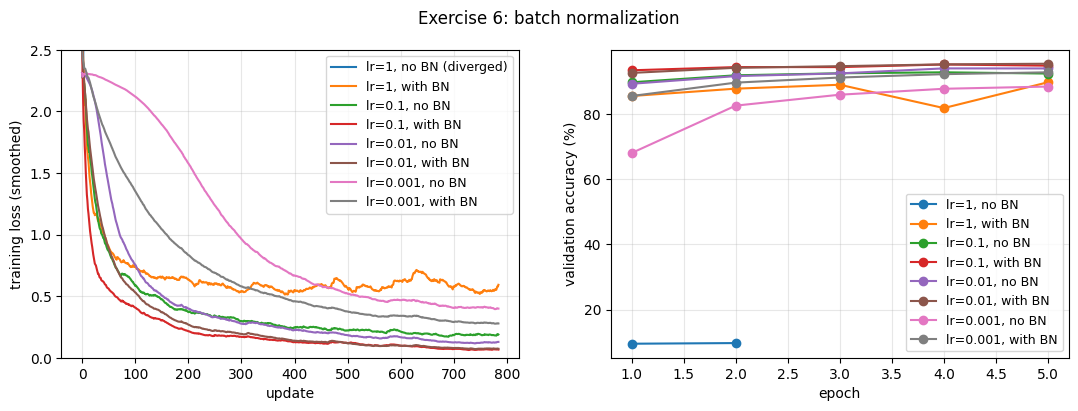


eval mode (running statistics)            : val acc 95.38%  (val loss 0.1568)
train mode, mini-batches of    8 examples: val acc 85.15%
train mode, mini-batches of   64 examples: val acc 94.75%
train mode, mini-batches of 2000 examples: val acc 95.42%


In [21]:
# Exercise 6: batch normalization
# SGD(lr, momentum=0.9), batch size 64, 5 epochs, first 10,000 training examples.
# Each learning rate is trained once without and once with batch norm: 4 x 2 = 8 runs.
import copy

lrs6 = [1, 1e-1, 1e-2, 1e-3]
hists6, models6 = {}, {}                       # keys: (lr, batch_norm)

for lr in lrs6:
    for bn in [False, True]:
        tag = "with BN" if bn else "no BN"
        print(f"=== lr = {lr}, {tag} ===")
        model = make_model(seed=0, batch_norm=bn)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        loader = make_loader(batch_size=64, n_train=10_000)
        hists6[(lr, bn)] = fit(model, optimizer, loader, epochs=5, verbose=False)
        models6[(lr, bn)] = model              # keep the trained models for step 4

# 2. table of the best validation accuracy (* = diverged)
print("\nBest validation accuracy (%)   [* = diverged]")
print(f"{'learning rate':>14s} {'without BN':>12s} {'with BN':>12s}")
for lr in lrs6:
    cells = []
    for bn in [False, True]:
        h = hists6[(lr, bn)]
        cells.append(f"{max(h['val_acc']):9.2f}{'*' if h['diverged'] else ' '}  ")
    print(f"{lr:14} {cells[0]:>12s} {cells[1]:>12s}")

# extra table: final validation accuracy and final training loss
print("\nFinal val acc (%) / final train loss")
print(f"{'learning rate':>14s} {'without BN':>20s} {'with BN':>20s}")
for lr in lrs6:
    row = f"{lr:14}"
    for bn in [False, True]:
        h = hists6[(lr, bn)]
        row += f" {h['val_acc'][-1]:9.2f} / {h['train_loss'][-1]:7.4f}  "
    print(row)

# 3. plot the eight runs
plot_history({f"lr={lr}, {'with BN' if bn else 'no BN'}": h for (lr, bn), h in hists6.items()},
             "Exercise 6: batch normalization")

# 4. the BN model trained with lr = 1e-2: eval mode vs train mode with mini-batches of 8
bn_model = models6[(1e-2, True)]

def accuracy_train_mode(model, X, y, batch_size):
    m = copy.deepcopy(model)                   # work on a copy: a forward pass in train mode
    m.train()                                  # would otherwise overwrite the running statistics
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            correct += (m(xb).argmax(dim=1) == yb).sum().item()
    return 100 * correct / len(X)

val_loss_eval, val_acc_eval = evaluate(bn_model, X_val, y_val)           # eval mode (running statistics)
print(f"\neval mode (running statistics)            : val acc {val_acc_eval:.2f}%  (val loss {val_loss_eval:.4f})")
for bs in [8, 64, 2000]:                       # 8 is the one asked; 64 and 2000 are extra, for comparison
    print(f"train mode, mini-batches of {bs:4d} examples: val acc {accuracy_train_mode(bn_model, X_val, y_val, bs):.2f}%")

**Exercise 6: your observations and explanation.** *Write here.*
**Exercise 6: your observations and explanation.**

### 1. What was done

The MLP was trained with SGD with momentum 0.9, batch size 64, for 5 epochs on 10,000 training images, with four learning rates $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$. For each learning rate there is one model **without** batch normalization and one **with** it (a `BatchNorm1d` layer after each hidden linear layer, before the ReLU). The two models have the same architecture, the same data and the same mini-batch order, so the only difference is the BN layers. Then, for the BN model trained with $\alpha = 10^{-2}$, the validation accuracy was measured in `eval()` mode and in `train()` mode with mini-batches of 8 examples.

### 2. Background: what batch normalization does

**The problem.** While a layer is learning, the outputs of the previous layers keep changing, so the inputs of every layer have a distribution (mean and spread) that shifts at every update. The scale of the activations can also grow or shrink from one layer to the next. Large values make the gradients large and the training fragile, which is why a large learning rate often makes a network unstable.

**The idea.** For every hidden unit, normalize its pre-activation $z$ over the current mini-batch of $B$ examples, then let the network re-scale it with two learned parameters:

$$\mu_B = \frac{1}{B}\sum_i z_i, \qquad \sigma_B^2 = \frac{1}{B}\sum_i (z_i-\mu_B)^2, \qquad \hat z_i = \frac{z_i-\mu_B}{\sqrt{\sigma_B^2+\epsilon}}, \qquad \tilde z_i = \gamma\,\hat z_i + \beta .$$

* $\hat z$ has mean 0 and variance 1 over the mini-batch, whatever the weights of the previous layer are. So every ReLU receives inputs of a fixed, sensible scale.
* $\gamma$ (scale) and $\beta$ (shift) are **learned**, so the network can still choose any mean and spread if it is useful.
* The linear layer before BN has **no bias** (`bias=False` in the code): BN subtracts the mean, which would cancel any constant added by a bias, and $\beta$ plays that role.

**Train mode and eval mode (the key difference).**

* **Training (`model.train()`):** $\mu_B$ and $\sigma_B^2$ are computed from **the current mini-batch**. The output for one image therefore depends on the other images in its batch (this adds some noise, which acts as a mild regularizer). At the same time BN keeps **running averages** of the means and variances seen during training (PyTorch's momentum 0.1, so they follow roughly the last 10 batches).
* **Evaluation (`model.eval()`):** the **running averages** are used instead of batch statistics, so the output for an image does not depend on the other images and does not change with the batch size. This is what `evaluate` does.

The two modes agree only if the statistics of the evaluation batches are close to the running averages, which requires batches large enough to be representative.

**Why it helps (the usual explanations).**

1. **Stable scale of the activations and gradients** in every layer, so a much larger learning rate can be used without the loss exploding.
2. **Less sensitivity to the initialization** and to the scale of the weights: multiplying all the weights of a layer by a constant does not change the output of BN.
3. **Faster convergence**: the loss surface is better conditioned, so fewer updates are needed to reach a given loss.
4. A **small regularization effect** from the noise of the mini-batch statistics.

### 3. Results

**Best validation accuracy (%)** (`*` = diverged: the loss became `nan`)

| Learning rate | without BN | with BN | gain from BN |
|---|---|---|---|
| 1 | 9.72* | 89.70 | +79.98 |
| $10^{-1}$ | 92.75 | 95.15 | +2.40 |
| $10^{-2}$ | 93.95 | **95.38** | +1.43 |
| $10^{-3}$ | 88.38 | 92.75 | +4.37 |

**Final validation accuracy (%) / final training loss**

| Learning rate | without BN | with BN |
|---|---|---|
| 1 | 9.72 / nan | 89.70 / 0.5589 |
| $10^{-1}$ | 92.37 / 0.1839 | 94.78 / **0.0645** |
| $10^{-2}$ | 93.93 / 0.1195 | **95.38** / 0.0717 |
| $10^{-3}$ | 88.38 / 0.3992 | 92.75 / 0.2777 |

**Consistency check with Exercises 3 and 4.** The "without BN" column at $10^{-1}$, $10^{-2}$ and $10^{-3}$ (92.75, 93.95, 88.38) is exactly what SGD with momentum 0.9 gave in those exercises, so the pipeline is the same.

**Step 4: the BN model trained with $\alpha = 10^{-2}$ (same weights, different mode)**

| Evaluation | Validation accuracy |
|---|---|
| `eval()` mode (running statistics), whole validation set | **95.38%** (val loss 0.1568) |
| `train()` mode (batch statistics), mini-batches of **8** | **85.15%** |
| (extra) `train()` mode, mini-batches of 64 | 94.75% |
| (extra) `train()` mode, mini-batches of 2000 | 95.42% |

### 4. Observations

1. **Batch norm improved the accuracy at every learning rate, and the gain depends on the learning rate.**
   * At the best rate of each model, BN gives 95.38% (at $10^{-2}$) against 93.95% without BN: +1.4 points. The gap is about 86 validation images, well above the uncertainty of about 0.3 points for one accuracy.
   * The gains are +2.4 points at $10^{-1}$ and **+4.4 points at $10^{-3}$** (the plain model's weakest usable case), and **+80 points at $\alpha = 1$**.
2. **Without BN, training breaks at $\alpha = 1$; with BN it trains.** The plain run's loss became `nan` during epoch 2 (`fit` stopped it; only 2 epochs appear in the figure) and its accuracy stayed at 9.72%, i.e. random guessing for 10 classes. With BN the same learning rate gives 89.70%. It is **not clean**, though: its training loss stays high and noisy (about 0.55 to 0.6 at the end, against 0.07 for $10^{-1}$ and $10^{-2}$), and its validation accuracy dips to about 82% at epoch 4 before recovering to 89.7% at epoch 5. So BN made training *possible* at $\alpha = 1$, not *good*.
3. **BN makes the network less sensitive to the learning rate.** Across the four rates, the accuracy without BN ranges from failure (9.72%) to 93.95%. With BN, it ranges from 89.70% to 95.38%: the worst case is still a working model, and **three of the four rates give 92.75% or more** (without BN: two).
4. **At the small rate $10^{-3}$, BN is much faster.** The loss without BN stays on a plateau near 2.3 for the first ~100 updates, then falls slowly and ends at 0.399; with BN the loss starts falling at once and ends at 0.278. After the first epoch the accuracy is about 85.5% with BN and about 68% without. Both are still improving at epoch 5, but BN is far ahead. (Curiously, BN at $10^{-3}$ gives 92.75%, the same number as the plain model at $10^{-1}$, a rate 100 times larger.)
5. **At the other rates the training loss is lower with BN**, and the loss curves descend faster in the figure: at $10^{-1}$ the final loss is 0.0645 against 0.1839, and at $10^{-2}$ it is 0.0717 against 0.1195. The best training loss of the table (0.0645) is at $10^{-1}$, but the best validation accuracy is at $10^{-2}$ (95.38%); the difference between $10^{-1}$ and $10^{-2}$ with BN (95.15 against 95.38) is only 0.23 points, within the noise, so the two are equivalent. With BN the final accuracy at $10^{-1}$ (94.78%) is also a little below its best (95.15%), a small sign of noise at the larger rate.
6. **Step 4: the same trained model gives very different accuracies in the two modes.** In `eval()` mode it gives 95.38%, and in `train()` mode with mini-batches of 8 examples it gives **85.15%, a drop of 10.2 points**. The drop shrinks as the mini-batch grows: **94.75% with 64 examples** (−0.6 point), and **95.42% with 2000 examples**, which equals the eval-mode result within 0.04 points (about 2 images, so the same).

### 5. Explanations

* **Why BN allows larger learning rates.** Without BN, a large step can make the weights of a layer large, which makes the activations and then the gradients larger, which gives even larger steps: the explosion of SGD at $\alpha = 1$ in Exercise 1 and of this plain model at $\alpha = 1$ (effective rate 10 with momentum). With BN, each hidden unit is re-normalized at every update, so a change in the scale of the incoming weights does not change the output of the layer. The activations stay at a controlled scale, and the same learning rate is much less dangerous. This explains why BN is better at every rate here, and why the loss is much less sensitive to the exact choice of $\alpha$.
* **Why BN is much faster at a small learning rate.** Without BN, the initial scale of the activations is not adapted, and at $\alpha = 10^{-3}$ the plain network needs about 100 updates to leave the plateau at loss 2.3. With BN, every layer receives inputs of a fixed scale, so every layer learns at a comparable speed from the first update, and the loss falls immediately.
* **Why BN at $\alpha = 1$ is still not good.** The output layer (the 10 logits) has **no BN after it**, so it is still exposed to a huge step. A step of effective size 10 on the last layer causes the noisy loss and the dip at epoch 4. BN widens the range of learning rates that work; it does not remove the need to choose one.
* **Why the plain model fails at $\alpha = 1$ but the BN model does not.** In the plain model nothing limits the growth of the activations after a big step, so the loss reaches `nan`. In the BN model the hidden layers stay normalized; only the last layer can misbehave, and it recovers because its inputs remain bounded.
* **Why eval mode and train mode give different accuracies (step 4).** In train mode each prediction is normalized with the mean and variance **of the 8 images in its batch**. With only 8 examples these statistics are very noisy estimates of the true ones (a batch may contain mostly one class, or none of some digits), so the normalization changes randomly from batch to batch, and the later layers receive activations shifted relative to what they learned: 10 points of accuracy are lost. The model was trained with batches of 64, so with batches of 64 the statistics are already reasonably stable (−0.6 point, which is the remaining noise), and with batches of 2000 they are almost exactly the population statistics, which is what the running averages approximate, so the accuracy equals the eval-mode one. In eval mode the fixed running averages are used, so the prediction for one image does not depend on which other images are in the batch, which is what we need at test time (an image must receive the same answer whatever comes with it).
* **The practical lessons of step 4.** (1) Always call `model.eval()` before evaluating a BN model (the helper `evaluate` does). Forgetting it makes the result depend on the batch size and on the other examples. (2) BN needs reasonably large batches during training as well, since small batches give noisy statistics and poor running averages. When batches must be small, alternatives that do not use batch statistics (LayerNorm, GroupNorm) are used. (3) A forward pass in train mode modifies the running statistics, so the experiment was done on a copy of the model.
* **A caution.** One run per setting, 5 epochs, and a 6,000-image validation set (one image is 0.017 points; the uncertainty of one accuracy is about 0.3 points). Differences of less than half a point (for example 95.15 against 95.38) should not be interpreted, but the large effects (the failure at $\alpha=1$, the gap of 4.4 points at $10^{-3}$, the 10-point train/eval gap) are far above that level. Also, the BN and plain models do not start from exactly the same weights (BN has no biases and extra layers), which is part of the "BN effect" by definition. The slow runs ($10^{-3}$) were still improving at epoch 5.

### 6. Conclusion

Batch normalization normalizes the pre-activations of each hidden layer with the statistics of the mini-batch, then re-scales them with learned $\gamma$ and $\beta$. In this experiment it:

* **improved the accuracy at every learning rate**: 95.38% against 93.95% at the best rate, 92.75% against 88.38% at $10^{-3}$, and 89.70% against a diverged run at $\alpha = 1$;
* **made training faster** (lower training loss at the same learning rate, no plateau at $10^{-3}$) and **much less sensitive to the learning rate** (the worst case is a working model);
* **requires care at evaluation**: `eval()` mode (running statistics) gives the stable 95.38%, while `train()` mode with tiny batches of 8 examples loses 10 points (85.15%), and the loss shrinks as the batch grows (94.75% with 64, 95.42% with 2000).

The learning rate still has to be chosen (the output layer has no BN, and $\alpha = 1$ is noisy even with BN), but BN makes the choice much easier, which is why it is a standard component of deep networks.

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

epoch  1 | lr 5.00e-02 | train loss 0.2079 | val loss 0.1304 | val acc 96.07% | 1.8 s
epoch  2 | lr 4.88e-02 | train loss 0.0918 | val loss 0.0875 | val acc 97.22% | 3.6 s
epoch  3 | lr 4.52e-02 | train loss 0.0654 | val loss 0.0718 | val acc 97.77% | 5.4 s
epoch  4 | lr 3.97e-02 | train loss 0.0478 | val loss 0.0698 | val acc 97.88% | 7.7 s
epoch  5 | lr 3.27e-02 | train loss 0.0343 | val loss 0.0655 | val acc 98.03% | 9.5 s
epoch  6 | lr 2.50e-02 | train loss 0.0240 | val loss 0.0638 | val acc 98.18% | 11.3 s
epoch  7 | lr 1.73e-02 | train loss 0.0169 | val loss 0.0624 | val acc 98.17% | 13.1 s
epoch  8 | lr 1.03e-02 | train loss 0.0128 | val loss 0.0600 | val acc 98.18% | 15.0 s
epoch  9 | lr 4.77e-03 | train loss 0.0109 | val loss 0.0605 | val acc 98.07% | 16.8 s
epoch 10 | lr 1.22e-03 | train loss 0.0097 | val loss 0.0603 | val acc 98.13% | 18.8 s

epoch | learning rate | train loss | val loss | val acc
    1 |       0.05000 |     0.2079 |   0.1304 |  96.07%
    2 |       0.04878 

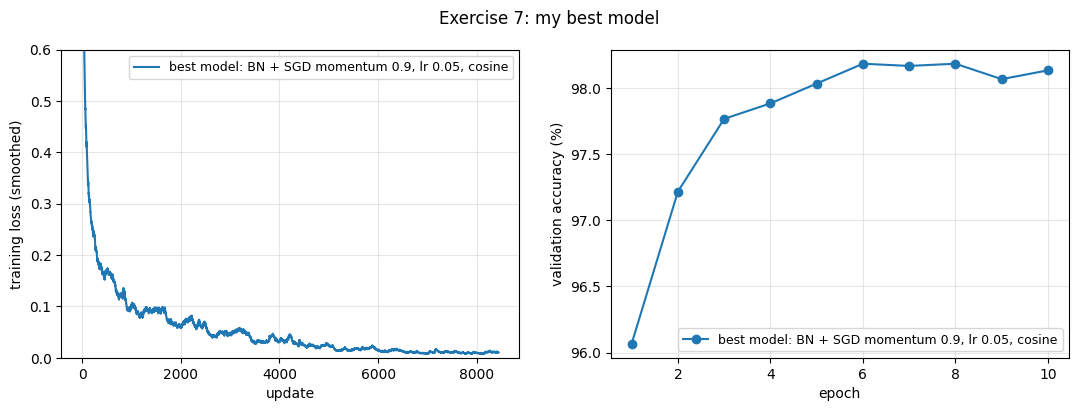

In [22]:
# Exercise 7: my best model
# Choices (each one is justified in the markdown cell below):
#   batch norm: yes | optimizer: SGD + momentum 0.9 | lr: 0.05 | schedule: cosine annealing (T_max = 10)
#   batch size: 64  | data: the FULL training set (54,000 images) | 10 epochs

EPOCHS7 = 10

best_model = make_model(seed=0, batch_norm=True)
optimizer = optim.SGD(best_model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS7)
loader = make_loader(batch_size=64, n_train=None)                 # n_train=None -> all 54,000 training images

hist7 = fit(best_model, optimizer, loader, epochs=EPOCHS7, scheduler=scheduler, verbose=True)

# validation accuracy per epoch
print("\nepoch | learning rate | train loss | val loss | val acc")
for e in range(EPOCHS7):
    print(f"{e + 1:5d} | {hist7['lr'][e]:13.5f} | {hist7['train_loss'][e]:10.4f} | "
          f"{hist7['val_loss'][e]:8.4f} | {hist7['val_acc'][e]:6.2f}%")
print(f"\nbest val acc {max(hist7['val_acc']):.2f}% (epoch {hist7['val_acc'].index(max(hist7['val_acc'])) + 1}) "
      f"| final val acc {hist7['val_acc'][-1]:.2f}% | diverged: {hist7['diverged']}")

plot_history({"best model: BN + SGD momentum 0.9, lr 0.05, cosine": hist7},
             "Exercise 7: my best model", ylim=(0, 0.6))
# best_model is kept (trained, in eval-ready state) for Exercise 8: do NOT evaluate it on the test set here.

**Exercise 7: your observations and explanation.**

### 1. My configuration

| Choice | Value |
|---|---|
| Model | MLP 784 → 128 → 100 → 10 with ReLU **and batch normalization** |
| Optimizer | SGD with **momentum 0.9** |
| Learning rate | **0.05** (initial) |
| Schedule | **cosine annealing**, `T_max = 10` (one step per epoch) |
| Batch size | **64** |
| Data / epochs | the **full** training set (54,000 images), **10 epochs** (844 updates per epoch, 8,440 in total) |
| Initialization | `make_model(seed=0)` |

### 2. Why each choice (one reason from the previous exercises each)

* **Batch normalization: yes.** Exercise 6 showed that BN improved the accuracy at every learning rate (95.38% against 93.95% at the best rate of each model, 92.75% against 88.38% at $10^{-3}$) and made the network much less sensitive to the learning rate. It costs almost no time. The model is evaluated in `eval()` mode (as `evaluate` does), so the train/eval mismatch seen with mini-batches of 8 (a drop of 10 points) does not affect it.
* **Optimizer: SGD with momentum 0.9.** Exercise 3 showed that momentum 0.9 is much better than plain SGD at the same $\alpha$ (93.93% against 88.40% at $\alpha=0.01$) and more stable than plain SGD at a large rate. Exercise 4 showed that, at its best learning rate, it is as good as the adaptive optimizers: the six optimizers were within 0.56 points of each other (93.62% to 94.18%), too close to rank with one seed. I chose the simplest optimizer of the top group, which works well with a schedule. Adam with $\alpha = 10^{-3}$ would be an equally defensible choice.
* **Learning rate 0.05.** With BN and momentum 0.9, $\alpha = 10^{-1}$ gave 95.15% and $\alpha = 10^{-2}$ gave 95.38% (Exercise 6), both good, so the best value lies between them; 0.05 is about the middle of that range on a log scale. A large initial rate gives fast progress at the start, and the schedule handles the end. This value had not been tested with BN before, so it was an interpolation; the result below shows that it was a good one (no instability at any epoch).
* **Schedule: cosine annealing.** In Exercise 5 the constant rate was noisy at the end (final accuracy 94.33%, validation loss 0.33, a drop of 1.5 points in the last two epochs), whereas the cosine schedule gave the best final result (96.07%, training loss 0.0026) and the steadiest validation curve. Decaying the rate removes the noise of large steps at the end. I use `T_max = 10`, the number of epochs, so the rate falls to nearly zero exactly at the end of training and the "decays too early" failure of Exercise 5 is avoided.
* **Batch size 64.** Exercise 2 showed that a mini-batch of about 32 to 64 is the best compromise: stable at both learning rates tested and fast per epoch (a batch of 1 was about 27 times slower per epoch and diverged at $\alpha = 0.1$; a very large batch makes too few updates). A batch of 64 also keeps the BN statistics reliable (Exercise 6, step 4: only 0.6 point lost in train mode with batches of 64).
* **Full training set, 10 epochs.** The previous experiments used only 10,000 images. The full training set has 54,000 images (5.4 times more), so each epoch has 844 updates instead of 157, and 10 epochs are 8,440 updates, more than 10 times the budget of the earlier runs. This is enough for the cosine schedule to bring the rate down gradually.

### 3. Validation accuracy per epoch

| Epoch | Learning rate | Train loss | Val loss | Val accuracy |
|---|---|---|---|---|
| 1 | 0.05000 | 0.2079 | 0.1304 | 96.07% |
| 2 | 0.04878 | 0.0918 | 0.0875 | 97.22% |
| 3 | 0.04523 | 0.0654 | 0.0718 | 97.77% |
| 4 | 0.03969 | 0.0478 | 0.0698 | 97.88% |
| 5 | 0.03273 | 0.0343 | 0.0655 | 98.03% |
| 6 | 0.02500 | 0.0240 | 0.0638 | **98.18%** |
| 7 | 0.01727 | 0.0169 | 0.0624 | 98.17% |
| 8 | 0.01031 | 0.0128 | **0.0600** | **98.18%** |
| 9 | 0.00477 | 0.0109 | 0.0605 | 98.07% |
| 10 | 0.00122 | **0.0097** | 0.0603 | 98.13% |

**Best validation accuracy: 98.18%** (epochs 6 and 8). **Final validation accuracy (epoch 10): 98.13%.** The run did not diverge, and the whole training took about 21 seconds.

The learning-rate column follows the schedule $\alpha_t = 0.025\,(1+\cos(\pi t/10))$, which confirms that the scheduler was stepped once per epoch.

### 4. Observations

1. **A large improvement over all the earlier exercises.** The final validation accuracy of 98.13% compares with 96.07% (Exercise 5, cosine, no BN, 10,000 images) and 95.38% (Exercise 6, BN, constant rate, 10,000 images). In terms of errors on the 6,000 validation images, there are about 112 errors now, against about 236 in Exercise 5: **the error rate is roughly halved** (from 3.9% to 1.9%).
2. **Most of the progress happens in the first epochs.** After one epoch (844 updates) the model already has 96.07%, as much as the best run of Exercise 5 reached after 10 epochs on 10,000 images. It reaches 97.22% after epoch 2 and 97.77% after epoch 3.
3. **The validation accuracy flattens from epoch 6.** The values from epoch 5 to epoch 10 are 98.03, 98.18, 98.17, 98.18, 98.07 and 98.13%: a total spread of 0.15 points, about 9 images. This is within the noise of the measurement (the standard error of one accuracy near 98% on 6,000 images is about 0.18 points), so I do not claim that epoch 6 is better than epoch 10. The best (98.18%) and the final (98.13%) accuracies differ by 0.05 points, which is 3 images.
4. **The training curve becomes smooth as the learning rate falls.** In the loss plot, the first 4,000 updates show visible bumps (for example around updates 1,500 to 2,500, when the rate is still above 0.04), and after about update 6,000 the curve is almost smooth, close to 0.01. The training loss decreases at every epoch (0.2079, 0.0918, ..., 0.0097).
5. **The validation loss stops improving after epoch 8 and is much higher than the training loss.** It decreases from 0.1304 to 0.0600 (epoch 8), then stays at 0.0605 and 0.0603. The final training loss is 0.0097, about 6 times lower than the validation loss (0.0603). The model fits the training set almost perfectly, and the generalization gap is now the main limit. However, the validation loss does **not rise** at the end, so there is no sign of harmful overfitting within these 10 epochs.
6. **In the first two epochs the training loss is above the validation loss** (epoch 1: 0.2079 against 0.1304), which looks surprising but is expected: the training loss is an average over the whole epoch, during which the model improves a lot, while the validation loss is measured once, at the end of the epoch. (With BN, the training pass also uses noisy batch statistics.) From epoch 3 the order is the usual one.

### 5. Explanations

* **Why more data and BN raise the accuracy.** With 54,000 images instead of 10,000, the model cannot memorize the training set as easily, so it generalizes better. BN gives faster and more stable training (Exercise 6). The two effects add up, and the larger number of updates (8,440 against 785) also lets the model converge further.
* **Why the schedule matters even with BN.** BN makes a large learning rate safe, but it does not remove the noise of mini-batch gradients near the minimum. The decaying rate shrinks the steps in the last epochs, which gives the smooth training loss and the stable validation curve (98.07 to 98.18% over the last five epochs), as in Exercise 5.
* **Why the accuracy stops improving even though the training loss still decreases.** From epoch 6 to 10 the training loss falls from 0.0240 to 0.0097, but the validation accuracy stays flat and the validation loss barely changes. Once the model classifies almost all training images correctly with high confidence, further training only increases that confidence on images it already gets right; it does not teach anything that helps on new images. The remaining errors of the validation set are the images that this small MLP cannot classify correctly (ambiguous or unusual digits).
* **Why I did not tune further.** Each choice came from the validation results of Exercises 1 to 6; the test set was never used. Differences of a few tenths of a percent between reasonable configurations (SGD or Adam, $\alpha = 0.03$ or $0.1$) cannot be distinguished on 6,000 validation images with one seed (uncertainty about 0.2 points), so more tuning on this set would mostly fit its noise.
* **Limits of this choice.** The learning rate 0.05 was not compared with its neighbours with BN on the full data. The model is a small MLP, and its accuracy is limited by the architecture: a convolutional network, which uses the 2D structure of the image, reaches clearly higher accuracy on MNIST. Also, the model that is carried to Exercise 8 is the one **after epoch 10** (its validation accuracy is 98.13%), not the best epoch (98.18%), because `fit` does not save the weights of the best epoch; the difference is within the noise.

### 6. Conclusion

The final model combines the findings of the previous exercises: **batch normalization** (Exercise 6), **SGD with momentum 0.9** (Exercises 3 and 4), a **medium-large learning rate (0.05) decayed with a cosine schedule** (Exercises 1 and 5), and a **batch size of 64** (Exercise 2), trained on the **full** training set for 10 epochs (about 21 seconds). It reaches a validation accuracy of **98.13%** after the last epoch (best 98.18%), halving the error rate of the 10,000-image experiments (96.07%). Its training loss (0.0097) is far below its validation loss (0.0603), so the main limit is now generalization and the capacity of this small MLP, not the optimization. This model is the one evaluated on the test set in Exercise 8.

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [23]:
# Exercise 8: test accuracy
# best_model is the model trained in Exercise 7 (after epoch 10). The test set is used ONCE, here.

test_loss, test_acc = evaluate(best_model, X_test, y_test)      # evaluate() puts the model in eval mode
best_val_acc = max(hist7["val_acc"])
final_val_acc = hist7["val_acc"][-1]
n_errors = round((100 - test_acc) / 100 * len(X_test))

print(f"best validation accuracy  : {best_val_acc:.2f}%")
print(f"final validation accuracy : {final_val_acc:.2f}%   <- the accuracy of the model that is tested")
print(f"TEST accuracy             : {test_acc:.2f}%   ({n_errors} errors out of {len(X_test)} images)")
print(f"test loss                 : {test_loss:.4f}")
print(f"difference test - final validation: {test_acc - final_val_acc:+.2f} points")

best validation accuracy  : 98.18%
final validation accuracy : 98.13%   <- the accuracy of the model that is tested
TEST accuracy             : 98.35%   (165 errors out of 10000 images)
test loss                 : 0.0522
difference test - final validation: +0.22 points


**Exercise 8: your observations and explanation.** *Write here.*

### 1. Result

The model of Exercise 7 (MLP with batch normalization, SGD with momentum 0.9, $\alpha = 0.05$ with cosine annealing, batch size 64, full training set, 10 epochs) was evaluated **once** on the 10,000 test images, in `eval()` mode.

| | Accuracy | Loss | Errors |
|---|---|---|---|
| Best validation accuracy (epochs 6 and 8) | 98.18% | | |
| Final validation accuracy (the model that was tested, epoch 10) | 98.13% | 0.0603 | about 112 of 6,000 |
| **Test accuracy** | **98.35%** | **0.0522** | **165 of 10,000** |

The test accuracy is **0.22 points higher** than the final validation accuracy (98.35% against 98.13%). The error rate is 1.65% on the test set and about 1.87% on the validation set.

### 2. Background: why the test set is used only once

The three sets have different roles:

* the **training set** is used to learn the parameters;
* the **validation set** is used to *choose* things: the optimizer, the learning rate, the schedule, the batch size, batch norm (Exercises 1 to 7);
* the **test set** is used only to *report* the final performance.

Every time we compare configurations on the validation set and keep the best one, we pick the configuration that does best on **that particular set of images**, partly because it is truly better and partly by luck. So the validation accuracy of the chosen model is slightly **optimistic**. The test set was not used for any decision, so it gives an **unbiased estimate** of the accuracy on new data. If we had used it to choose a configuration, it would have become another validation set and the number reported would be optimistic too. This is why it was kept for the very end and used once.

### 3. Observations

* **The test accuracy is 98.35%**, with 165 errors out of 10,000 images, and a test loss of 0.0522.
* **It is very close to the validation accuracy** (98.13%), only 0.22 points higher, which is about 22 images out of 10,000. The test loss (0.0522) is also close to the validation loss (0.0603), and a little lower.
* **The two measures agree on the same picture.** The generalization is good: the model that fits the training set almost perfectly (training loss 0.0097) is just as accurate on images it has never seen, from a different set of writers.
* **Comparison with the earlier exercises.** The earlier configurations used 10,000 training images and had validation accuracies of 93% to 96% (for example 96.07% in Exercise 5 and 95.38% in Exercise 6, an error rate of about 4% to 5%). The final model has an error rate of **1.65% on the test set**, roughly 2.5 times lower than the best earlier validation result.

### 4. Explanations

* **How large a difference is expected, and why.** A measured accuracy has a statistical uncertainty, because it is computed on a finite sample. For an accuracy $p$ on $n$ images, the standard error is $\sqrt{p(1-p)/n}$. Near $p = 0.98$:
  * on the 6,000 validation images: $\sqrt{0.98 \times 0.02 / 6000} \approx 0.18$ points;
  * on the 10,000 test images: $\sqrt{0.98 \times 0.02 / 10000} \approx 0.14$ points.
  Together, the difference between the two measurements has an uncertainty of about $\sqrt{0.18^2 + 0.14^2} \approx 0.23$ points. The observed difference of **+0.22 points is about one standard error**, so it is entirely compatible with sampling noise and does not need another explanation. The test accuracy is also the more precise of the two measurements, because it uses more images.
* **No sign of an optimistic validation estimate.** The selection on the validation set could make its accuracy slightly too high, so the test accuracy could be somewhat lower. Here it is *higher*, so this experiment shows no trace of that effect. One run cannot measure a small bias, but it does show that the choices of Exercises 1 to 7 did not overfit the validation set in any visible way. This is consistent with how the choices were made: a few configurations, and decisions based on large effects (BN, momentum, a decaying rate), not on tiny differences.
* **A test accuracy a bit above the validation accuracy is not unusual.** The two sets are different samples, and a random sample of 6,000 images of the training set can be a little harder or easier than the 10,000 test images (which come from different writers). The difference here is too small to say anything more, and I did not test any further explanation.
* **What the number means and what it does not.** About 98.35% of new handwritten digits from this kind of source are classified correctly. It is the performance of **this model after this single training run**: another seed would give different weights and a test accuracy that differs by a few tenths of a point. It is not a guarantee for other kinds of data (a different writing style, other scanners, other image sizes).
* **Why 98% is not the end.** The training loss (0.0097) is much lower than the validation loss (0.0603) and the test loss (0.0522): the model fits the training set almost perfectly, so the remaining 165 errors come from limited generalization and from the limited capacity of a small MLP, which does not use the 2D structure of the images. A convolutional network would reach a clearly higher accuracy on MNIST. More tuning of the learning rate would help little: the differences between reasonable configurations are below the uncertainty of the measurement (about 0.15 to 0.2 points).

### 5. Conclusion

The final model reaches a **test accuracy of 98.35%** (165 errors out of 10,000 images, test loss 0.0522), against a validation accuracy of 98.13% (best 98.18%). The two numbers agree within the expected statistical uncertainty (the difference of 0.22 points is about one standard error), which confirms that the choices made with the validation set in Exercises 1 to 7 generalized and were not overfitted to it. The test set was used once and no choice was made after seeing it, so 98.35% is an honest estimate of the accuracy of this model on new data. The whole pipeline, from the learning rate (Exercise 1) to batch normalization (Exercise 6), brought the error rate from about 4% to 5% (small-data experiments) to 1.65%.

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

100%|██████████| 170M/170M [20:23<00:00, 139kB/s]


channel mean: [0.49165481328964233, 0.4823332130908966, 0.4466792047023773] | channel std: [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]
train (45000, 3072) | val (5000, 3072)
train mean/std after normalization: 2.4295948151120683e-06 1.0
=== (a) ===
epoch  1 | lr 5.00e-02 | train loss 1.6850 | val loss 1.4867 | val acc 46.84% | 1.8 s
epoch  2 | lr 4.88e-02 | train loss 1.4193 | val loss 1.4297 | val acc 49.32% | 3.7 s
epoch  3 | lr 4.52e-02 | train loss 1.2962 | val loss 1.3485 | val acc 51.78% | 5.5 s
epoch  4 | lr 3.97e-02 | train loss 1.2002 | val loss 1.3132 | val acc 53.52% | 7.4 s
epoch  5 | lr 3.27e-02 | train loss 1.0977 | val loss 1.2968 | val acc 54.64% | 9.4 s
epoch  6 | lr 2.50e-02 | train loss 1.0009 | val loss 1.2974 | val acc 55.54% | 11.5 s
epoch  7 | lr 1.73e-02 | train loss 0.8917 | val loss 1.3202 | val acc 55.82% | 13.4 s
epoch  8 | lr 1.03e-02 | train loss 0.7896 | val loss 1.3368 | val acc 55.72% | 15.2 s
epoch  9 | lr 4.77e-03 | train loss 0.6884

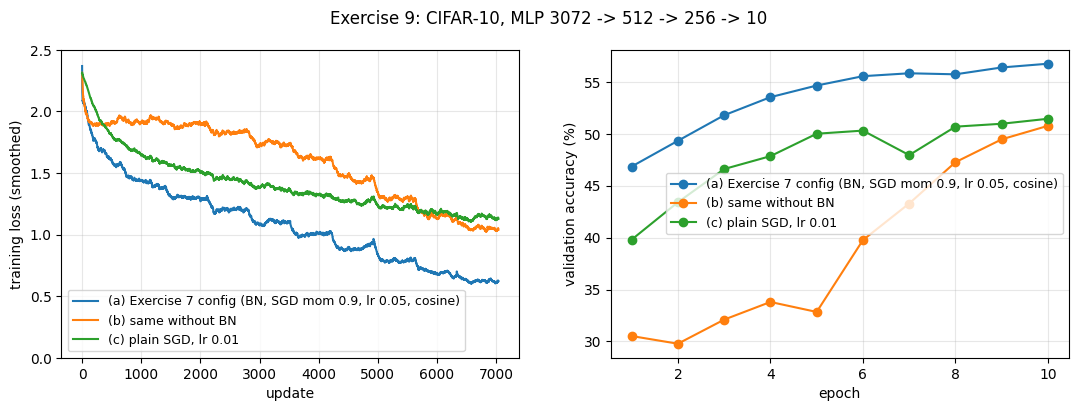


run                                                         best val acc  final val acc  train loss  val loss  diverged
(a) Exercise 7 config (BN, SGD mom 0.9, lr 0.05, cosine)          56.74%         56.74%      0.6218    1.3439     False
(b) same without BN                                               50.76%         50.76%      1.0517    1.5137     False
(c) plain SGD, lr 0.01                                            51.44%         51.44%      1.1344    1.3980     False
channel mean: [0.49165481328964233, 0.4823332130908966, 0.4466792047023773] | channel std: [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]
train (45000, 3072) | val (5000, 3072)
train mean/std after normalization: 2.4295948151120683e-06 1.0
=== (a) ===
epoch  1 | lr 5.00e-02 | train loss 1.6850 | val loss 1.4867 | val acc 46.84% | 1.8 s
epoch  2 | lr 4.88e-02 | train loss 1.4193 | val loss 1.4297 | val acc 49.32% | 3.9 s
epoch  3 | lr 4.52e-02 | train loss 1.2962 | val loss 1.3485 | val acc 51.78% | 

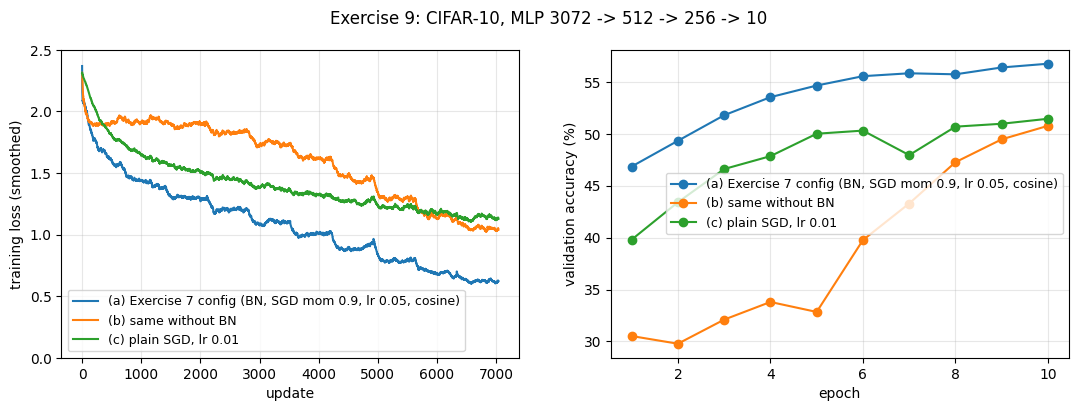


run                                                         best val acc  final val acc  train loss  val loss  diverged
(a) Exercise 7 config (BN, SGD mom 0.9, lr 0.05, cosine)          56.74%         56.74%      0.6218    1.3439     False
(b) same without BN                                               50.76%         50.76%      1.0517    1.5137     False
(c) plain SGD, lr 0.01                                            51.44%         51.44%      1.1344    1.3980     False


In [25]:
# Exercise 9 (optional): CIFAR-10
# WARNING: this cell REPLACES X_train, y_train, X_val, y_val with CIFAR-10 tensors (as the exercise asks),
# so make_loader / fit / evaluate work unchanged. Do Exercise 8 (MNIST test) BEFORE running it.
# The MNIST tensors are saved once in MNIST_BACKUP, in case you need them again.

if "MNIST_BACKUP" not in globals():
    MNIST_BACKUP = (X_train, y_train, X_val, y_val)

# 1. load CIFAR-10 (.data: numpy array (50000, 32, 32, 3), values 0-255; .targets: list of labels 0-9)
cifar_train = datasets.CIFAR10(root="data", train=True, download=True)
images = torch.from_numpy(cifar_train.data).float() / 255            # (50000, 32, 32, 3)
labels = torch.tensor(cifar_train.targets)                           # (50000,)

# 2. 45,000 images for training, 5,000 for validation
perm_c = torch.randperm(50000, generator=torch.Generator().manual_seed(42))
tr_idx, va_idx = perm_c[:45000], perm_c[45000:]

# one mean and one standard deviation per colour channel, from the TRAINING images only
mean_c = images[tr_idx].mean(dim=(0, 1, 2))                          # shape (3,)
std_c = images[tr_idx].std(dim=(0, 1, 2))                            # shape (3,)
print("channel mean:", mean_c.tolist(), "| channel std:", std_c.tolist())

def prep_cifar(idx):
    x = (images[idx] - mean_c) / std_c                               # broadcasting over the last axis (channels)
    return x.reshape(len(idx), -1)                                   # flatten: 32 * 32 * 3 = 3072 values

# 3. replace the MNIST tensors: make_loader, fit and evaluate now use CIFAR-10
X_train, y_train = prep_cifar(tr_idx), labels[tr_idx]
X_val, y_val = prep_cifar(va_idx), labels[va_idx]
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape))
print("train mean/std after normalization:", X_train.mean().item(), X_train.std().item())

# 4. three runs, 10 epochs, full training set, batch size 64
EPOCHS9 = 10
BN_FOR_C = False        # assumption for run (c): plain SGD = no momentum, no schedule, no batch norm

def run_cifar(name, batch_norm, make_opt, use_cosine):
    print(f"=== {name} ===")
    model = make_model(seed=0, n_in=3072, hidden=(512, 256), batch_norm=batch_norm)
    optimizer = make_opt(model.parameters())
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS9) if use_cosine else None
    loader = make_loader(batch_size=64, n_train=None)                # n_train=None -> all 45,000 images
    return fit(model, optimizer, loader, epochs=EPOCHS9, scheduler=scheduler, verbose=True)

hists9 = {
    "(a) Exercise 7 config (BN, SGD mom 0.9, lr 0.05, cosine)":
        run_cifar("(a)", True,  lambda p: optim.SGD(p, lr=0.05, momentum=0.9), True),
    "(b) same without BN":
        run_cifar("(b)", False, lambda p: optim.SGD(p, lr=0.05, momentum=0.9), True),
    "(c) plain SGD, lr 0.01":
        run_cifar("(c)", BN_FOR_C, lambda p: optim.SGD(p, lr=0.01), False),
}

plot_history(hists9, "Exercise 9: CIFAR-10, MLP 3072 -> 512 -> 256 -> 10", ylim=(0, 2.5))

print(f"\n{'run':58s} {'best val acc':>13s} {'final val acc':>14s} {'train loss':>11s} {'val loss':>9s} {'diverged':>9s}")
for name, h in hists9.items():
    print(f"{name:58s} {max(h['val_acc']):12.2f}% {h['val_acc'][-1]:13.2f}% "
          f"{h['train_loss'][-1]:11.4f} {h['val_loss'][-1]:9.4f} {str(h['diverged']):>9s}")

**Exercise 9: your observations and explanation.** *Write here.*

### 1. What was done

CIFAR-10 has 32 × 32 colour images of 10 classes (airplane, car, bird, ...). I kept 45,000 images for training and 5,000 for validation, normalized each of the 3 colour channels with the mean and standard deviation of the training images (means about 0.49, 0.48, 0.45; standard deviations about 0.25, 0.24, 0.26), and flattened every image into a row of $32 \times 32 \times 3 = 3072$ values. After normalization the training data has mean 0 and standard deviation 1. The model is the same kind of MLP as before with different sizes: $3072 \to 512 \to 256 \to 10$ with ReLU, about 1.7 million weights. Three runs, each for 10 epochs on the full training set with batch size 64 (704 updates per epoch, 7,040 in total):

* **(a)** my configuration of Exercise 7: batch norm, SGD with momentum 0.9, $\alpha = 0.05$, cosine annealing;
* **(b)** the same without batch norm;
* **(c)** plain SGD (no momentum, no schedule, no batch norm), $\alpha = 0.01$.

All runs start from `make_model(seed=0)` and see the mini-batches in the same order, so the differences come only from the settings above.

### 2. Background: why CIFAR-10 is much harder than MNIST for this model

* **Chance level is 10%**, as for MNIST, but the images are far more varied. A MNIST digit is a centred white stroke on a black background, almost the same in every image. A CIFAR-10 image is a natural photograph: the object can be anywhere, at any scale, in any orientation, with any background and colours, and the same class (a "bird") looks very different from one image to the next.
* **A fully connected network (MLP) treats the 3072 numbers as an unordered list.** It has no notion that two pixels are neighbours, and it must learn separately, for each position, what a feature looks like. If an object moves by a few pixels, all the inputs change and the network sees a new image. On MNIST the digits are centred, so this weakness barely matters; on CIFAR-10 it limits the accuracy a lot.
* **Convolutional networks** share one small filter over all positions and use the 2D structure; they reach more than 90% on CIFAR-10, far above what a plain MLP reaches.
* The model has **many more weights than information it can use**: about 1.7 million weights for 45,000 training images, so it can memorize the training set.

### 3. Results

| Run | Best val acc | Final val acc | Final train loss | Final val loss | Time (10 epochs) |
|---|---|---|---|---|---|
| (a) BN, SGD momentum 0.9, lr 0.05, cosine | **56.74%** | **56.74%** | **0.6218** | **1.3439** | about 19 s |
| (b) same without BN | 50.76% | 50.76% | 1.0517 | 1.5137 | about 17 s |
| (c) plain SGD, lr 0.01 | 51.44% | 51.44% | 1.1344 | 1.3980 | about 15 s |

None of the runs diverged. For comparison, the final model of Exercise 7 reached **98.13%** on the MNIST validation set.

**Validation accuracy at selected epochs**

| Epoch | (a) | (b) | (c) |
|---|---|---|---|
| 1 | 46.84% | 30.52% | 39.80% |
| 5 | 54.64% | 32.84% | 50.00% |
| 10 | 56.74% | 50.76% | 51.44% |

### 4. Observations

1. **The accuracy is far lower than on MNIST.** The best run reaches 56.74%, against 98.13% for MNIST: an error rate of about 43% instead of about 2%. It is well above the 10% of random guessing, so the model does learn, but it is a poor image classifier.
2. **Run (a) is clearly the best:** 56.74%, against 51.44% for (c) and 50.76% for (b), a gap of 5.3 to 6.0 points. The standard error of one accuracy near 55% on 5,000 images is about 0.7 points, so this gap is about 8 standard errors: it is reliable. Run (a) is ahead from the first epoch (46.84%, against 39.80% and 30.52%) and stays ahead.
3. **Run (b) (no BN) is the weakest, and its curve has a strange shape.** In epochs 1 and 2 its training loss does not move (1.9188, then 1.9206) and its accuracy stays around 30% (30.52%, then 29.78%). The loss starts to fall only in epochs 3 to 5, and then **improves quickly as the cosine schedule lowers the learning rate**: 32.84% (epoch 5), 39.76%, 43.28%, 47.26%, 49.46% and 50.76% (epoch 10). It is still improving at epoch 10 (+1.3 points in the last epoch), so it had not converged.
4. **(b) and (c) are not distinguishable.** They differ by 0.68 points (51.44% against 50.76%), about one standard error. The final training loss of (b) is lower (1.05 against 1.13) but its validation loss is higher (1.51 against 1.40).
5. **Run (c) learns slowly but steadily.** Its training loss decreases smoothly from 1.91 to 1.13 and it is still decreasing at epoch 10. Its validation accuracy has one dip (47.94% at epoch 7, with the validation loss rising to 1.53, then back to 50.68% at epoch 8), which is noise from the evaluation at one moment of training.
6. **Overfitting appears in run (a), and it appears in the loss rather than in the accuracy.**
   * The training loss falls to 0.6218, while the validation loss reaches its minimum at **epoch 5 (1.2968)** and then **rises** to 1.3439. The gap between training and validation loss at the end is 0.72 for (a), against 0.46 for (b) and 0.26 for (c).
   * The validation accuracy, however, does **not** go down: it keeps increasing slowly (54.64% at epoch 5, 55.54% at epoch 6, 56.74% at epoch 10).
   * So the loss increases while the accuracy still improves slightly.

### 5. Explanations

* **Why the same recipe gives 98% on MNIST and 57% on CIFAR-10.** The choices of Exercises 1 to 7 make the *optimization* work: batch norm, momentum, a decaying learning rate and a batch size of 64 reduce the training loss quickly, and they do here too (0.62 in 10 epochs for (a)). But the accuracy on new images is limited by what an MLP can represent from raw pixels, and for CIFAR-10 that is much less than for MNIST. The hard part of this problem is the architecture, not the optimizer.
* **Why BN helps so much here (+6 points, +16 points after epoch 1).** The same reasons as in Exercise 6: BN keeps the activations at a controlled scale, so the network trains quickly with a large rate. Run (b) uses the same large rate (0.05 with momentum 0.9, an effective rate of about 0.5) without BN. Its flat loss during epochs 1 and 2 and its sudden progress once the cosine schedule brings the rate down are consistent with a learning rate that is **too large for the unnormalized network** at the start (it bounces around instead of descending, as with the large rates of Exercise 1), and acceptable when it becomes smaller. This is my interpretation: I did not run (b) with a smaller rate, so I cannot say what it would reach. It also means that the BN gain measured here is partly a gain from a learning rate that suits BN but not the plain network.
* **Why the cosine schedule matters for (b).** Exercise 5 showed that decaying the rate improves the end of training. Run (b) is an extreme case: most of its accuracy gain happens in the second half, when the rate is below about 0.03.
* **Why the validation loss rises while the accuracy still improves.** The cross-entropy loss punishes confident wrong predictions heavily. As the model memorizes the training set, it becomes more confident everywhere, including on the validation images it gets wrong, which raises the average loss, while the number of correctly classified validation images can still increase a little. The same distinction between loss and accuracy appeared in Exercise 5. The minimum validation loss (epoch 5) is a sign that, for this model, more epochs mostly buy overfitting, and an earlier stop or more regularization (weight decay, dropout, data augmentation such as random flips and crops) would be natural next steps.
* **Why overfitting is much stronger for (a) than for (c).** Overfitting follows how well the optimizer fits the training set: (a) reaches a training loss of 0.62, (c) only 1.13. Run (c) is slow, so it has not yet had time to memorize the training set, and its smaller gap (0.26) is a result of undertraining rather than of better generalization. Its accuracy on validation is still lower.
* **Why the hyperparameters of Exercise 7 are not guaranteed to be best here.** They were chosen on MNIST. A different dataset, input size (3072 against 784) and number of classes can change the best learning rate and the best regularization. Run (a) shows that they transfer reasonably (no instability, steady improvement), but they are not tuned for CIFAR-10.
* **Caution.** One run per setting and a validation set of 5,000 images (one image is 0.02 points; the standard error of one accuracy near 55% is about 0.7 points). Differences below about 1.5 points, such as (b) against (c), should not be interpreted. The large effects (the gap to MNIST, the 5 to 6 points of (a), the plateau of (b) in the first epochs) are far above that level.

### 6. Conclusion

CIFAR-10 shows the limits of what I tuned in the other exercises. Batch normalization, momentum, a cosine schedule and a batch size of 64 give good optimization, and run (a) is the best of the three with **56.74%** validation accuracy, against 51.44% for plain SGD at $\alpha = 0.01$ and 50.76% for the same configuration without batch norm (the last two cannot be told apart). But a plain MLP on raw pixels stays far below its MNIST accuracy (98.13%) and starts to overfit after about 5 epochs: the training loss reaches 0.62 while the validation loss rises from 1.30 to 1.34. To do much better on this dataset I would need a model that uses the 2D structure of images (a convolutional network) and more regularization, not a better optimizer.